In [69]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
data25=pl.read_csv('/content/2025.csv')
data24=pl.read_csv('/content/2024.csv')
data23=pl.read_csv('/content/2023.csv')
data22=pl.read_csv('/content/2022.csv')
data21=pl.read_csv('/content/2021.csv')
data20=pl.read_csv('/content/2020.csv')
data19=pl.read_csv('/content/2019.csv')
data18=pl.read_csv('/content/2018.csv')

In [71]:
data25.head()

State,District,Date,Year,Month,Avg_rainfall,Agency_name
str,str,str,i64,i64,f64,str
"""Delhi""","""West""","""2025-02-23""",2025,2,0.0,"""NRSC VIC MODEL"""
"""Delhi""","""West""","""2025-03-11""",2025,3,0.0,"""NRSC VIC MODEL"""
"""Delhi""","""West""","""2025-03-14""",2025,3,0.599509,"""NRSC VIC MODEL"""
"""Delhi""","""West""","""2025-03-16""",2025,3,0.091965,"""NRSC VIC MODEL"""
"""Delhi""","""West""","""2025-03-21""",2025,3,0.0,"""NRSC VIC MODEL"""


In [72]:
data22.head()

State,District,Date,Year,Month,Avg_rainfall,Agency_name
str,str,str,i64,i64,f64,str
"""Delhi""","""South""","""2022-09-02""",2022,9,0.0,"""NRSC VIC MODEL"""
"""Delhi""","""South""","""2022-09-07""",2022,9,0.256,"""NRSC VIC MODEL"""
"""Delhi""","""South""","""2022-09-16""",2022,9,2.641,"""NRSC VIC MODEL"""
"""Delhi""","""South""","""2022-09-18""",2022,9,0.0,"""NRSC VIC MODEL"""
"""Delhi""","""South""","""2022-09-23""",2022,9,93.207,"""NRSC VIC MODEL"""


Date has been added as a string datatype, have to convert it to date time datatype and agency name and state has to be dropped as well


In [73]:
data25=data25.drop(['Agency_name','State'])
data24=data24.drop(['Agency_name','State'])
data23=data23.drop(['Agency_name','State'])
data22=data22.drop(['Agency_name','State'])
data21=data21.drop(['Agency_name','State'])
data20=data20.drop(['Agency_name','State'])
data19=data19.drop(['Agency_name','State'])
data18=data18.drop(['Agency_name','State'])


In [74]:
data25.head()

District,Date,Year,Month,Avg_rainfall
str,str,i64,i64,f64
"""West""","""2025-02-23""",2025,2,0.0
"""West""","""2025-03-11""",2025,3,0.0
"""West""","""2025-03-14""",2025,3,0.599509
"""West""","""2025-03-16""",2025,3,0.091965
"""West""","""2025-03-21""",2025,3,0.0


In [75]:
#change datatype of Date column to datetime
data24 = data24.with_columns(pl.col('Date').str.to_datetime().alias('Date'))
data23 = data23.with_columns(pl.col('Date').str.to_datetime().alias('Date'))
data22 = data22.with_columns(pl.col('Date').str.to_datetime().alias('Date'))
data21 = data21.with_columns(pl.col('Date').str.to_datetime().alias('Date'))
data20 = data20.with_columns(pl.col('Date').str.to_datetime().alias('Date'))
data19 = data19.with_columns(pl.col('Date').str.to_datetime().alias('Date'))
data18 = data18.with_columns(pl.col('Date').str.to_datetime().alias('Date'))


In [76]:
data25 = data25.with_columns(pl.col('Date').str.to_datetime().alias('Date'))


In [77]:
#extract month and day from the Date column
data25 = data25.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data24 = data24.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data23 = data23.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data22 = data22.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data21 = data21.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data20 = data20.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data19 = data19.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))
data18 = data18.with_columns(pl.col('Date').dt.month().alias('Month'),pl.col('Date').dt.day().alias('Day'))


In [78]:
#combining all the data into df
df=pl.concat([data25,data24,data23,data22,data21,data20,data19,data18])


In [79]:
# Convert the Polars DataFrame to a Pandas DataFrame for subsequent operations
df = df.to_pandas()

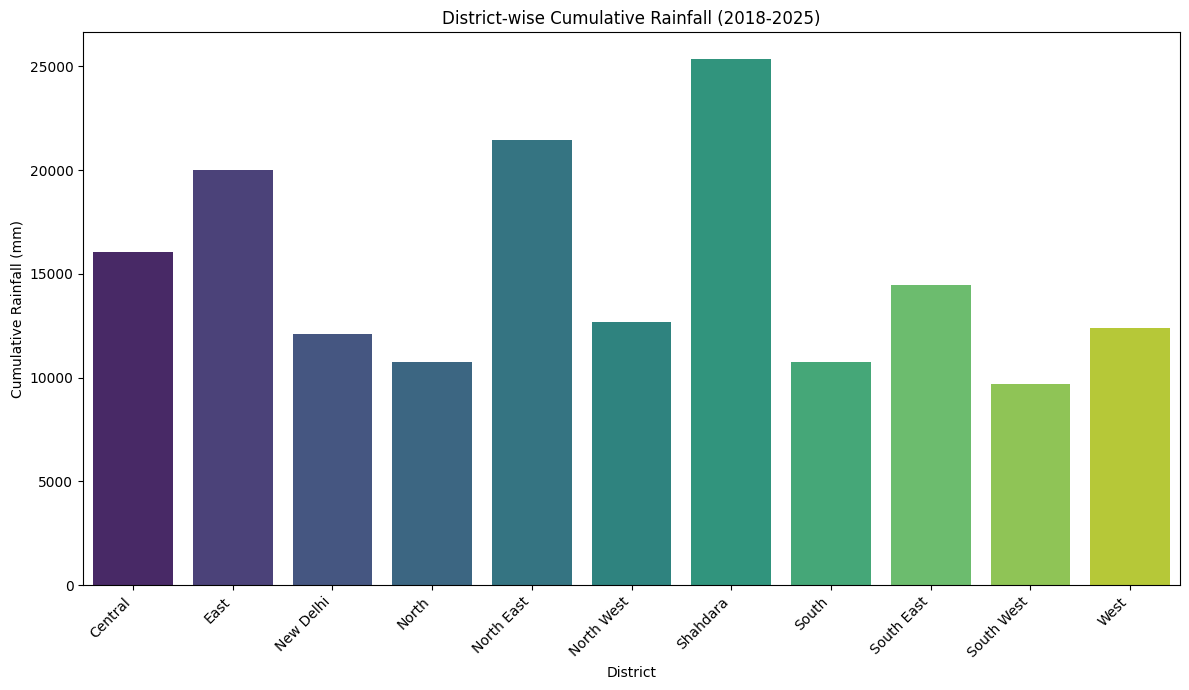

In [131]:
# Calculate cumulative rainfall per district
cumulative_rainfall_by_district = df.groupby('District')['Avg_rainfall'].sum().reset_index(name='Cumulative_Rainfall')

# Convert to Pandas for easier plotting with Seaborn/Matplotlib
pd_cumulative_rainfall = cumulative_rainfall_by_district

# Create the bar plot
plt.figure(figsize=(12, 7))
sns.barplot(x='District', y='Cumulative_Rainfall', data=pd_cumulative_rainfall, palette='viridis', hue='District', legend=False)
plt.title('District-wise Cumulative Rainfall (2018-2025)')
plt.xlabel('District')
plt.ylabel('Cumulative Rainfall (mm)')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

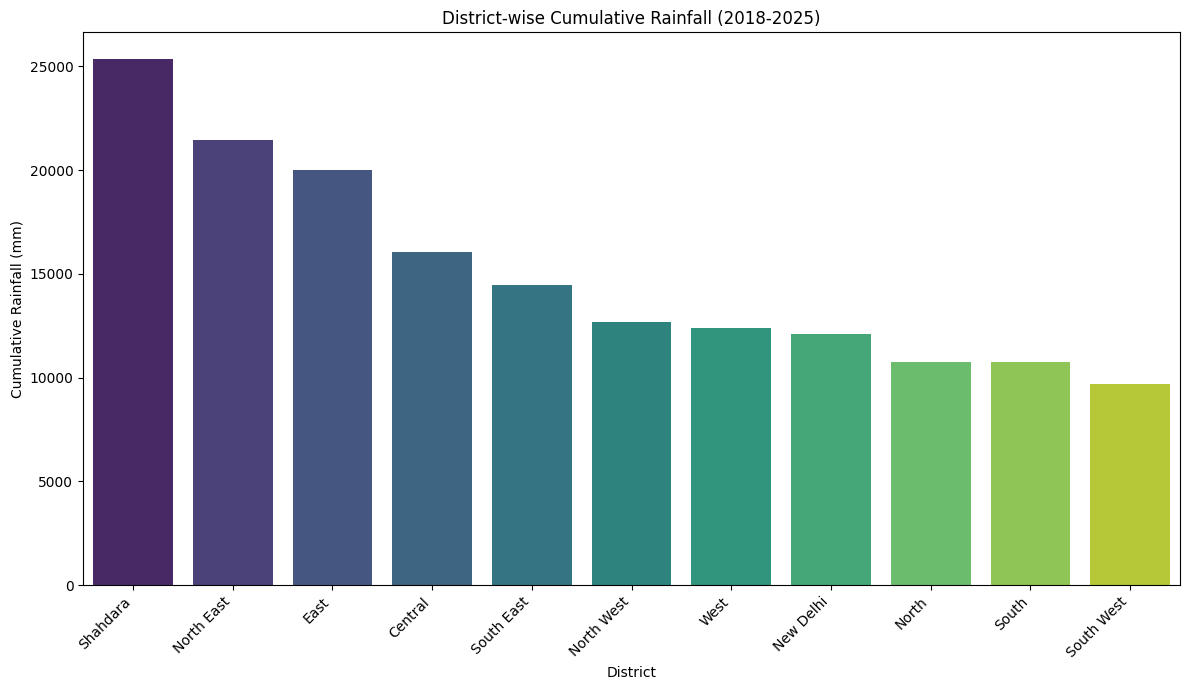

<Figure size 640x480 with 0 Axes>

In [138]:
import os

# Create a directory to save plots if it doesn't exist
if not os.path.exists('plots'):
    os.makedirs('plots')

# Calculate cumulative rainfall per district using Pandas syntax
cumulative_rainfall_by_district = df.groupby('District')['Avg_rainfall'].sum().reset_index(name='Cumulative_Rainfall')

# Sort in descending order
cumulative_rainfall_by_district = cumulative_rainfall_by_district.sort_values(by='Cumulative_Rainfall', ascending=False)

# pd_cumulative_rainfall is now the same as cumulative_rainfall_by_district
pd_cumulative_rainfall = cumulative_rainfall_by_district

# Create the bar plot
fig1 = plt.figure(figsize=(12, 7))
sns.barplot(x='District', y='Cumulative_Rainfall', data=pd_cumulative_rainfall, palette='viridis', hue='District', legend=False)
plt.title('District-wise Cumulative Rainfall (2018-2025)')
plt.xlabel('District')
plt.ylabel('Cumulative Rainfall (mm)')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()
plt.savefig('plots/district_wise_cumulative_rainfall.png')
plt.close(fig1) # Close the figure to free up memory

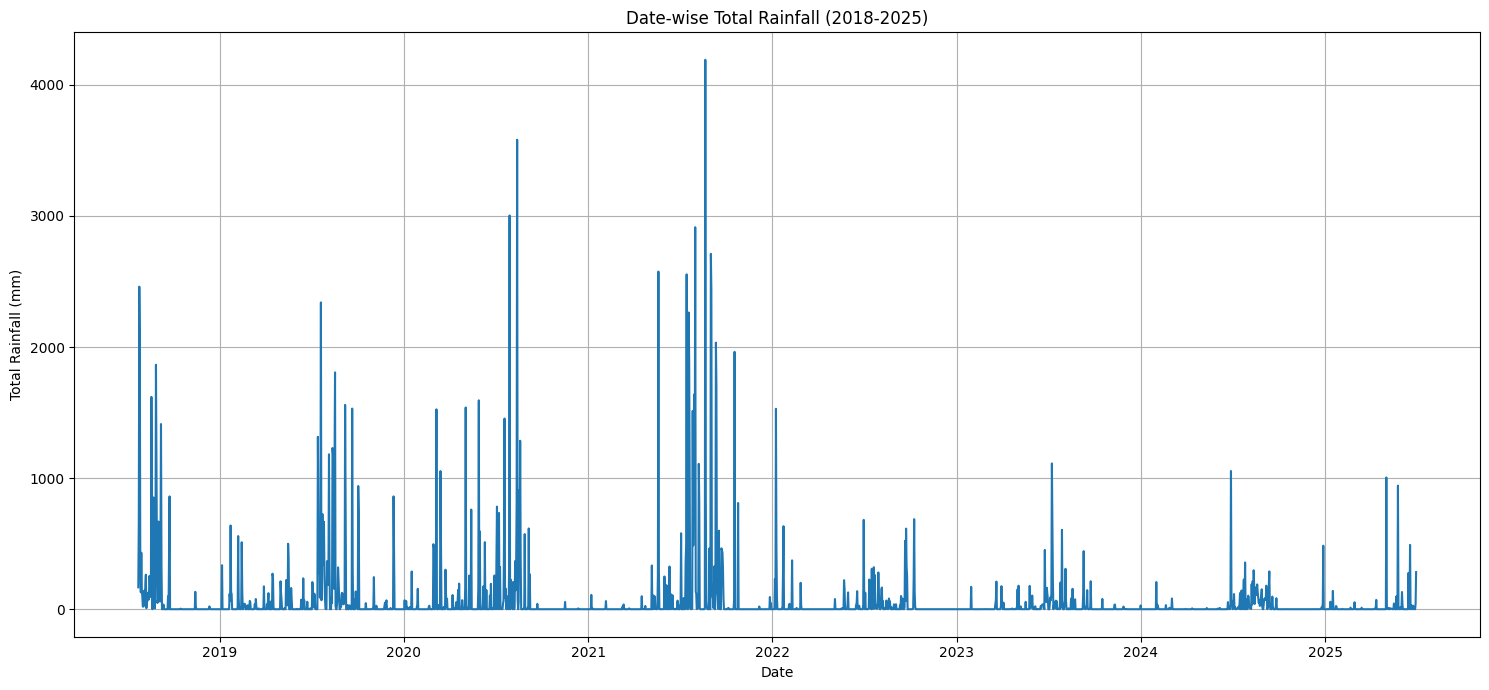

<Figure size 640x480 with 0 Axes>

In [94]:
date_wise_rainfall = df.groupby('Date')['Avg_rainfall'].sum().reset_index(name='Total_Daily_Rainfall')

pd_date_wise_rainfall = date_wise_rainfall

fig2 = plt.figure(figsize=(15, 7))
sns.lineplot(x='Date', y='Total_Daily_Rainfall', data=pd_date_wise_rainfall)
plt.title('Date-wise Total Rainfall (2018-2025)')
plt.xlabel('Date')
plt.ylabel('Total Rainfall (mm)')
plt.grid(True)
plt.tight_layout()
plt.show()
plt.savefig('plots/date_wise_total_rainfall.png')
plt.close(fig2)

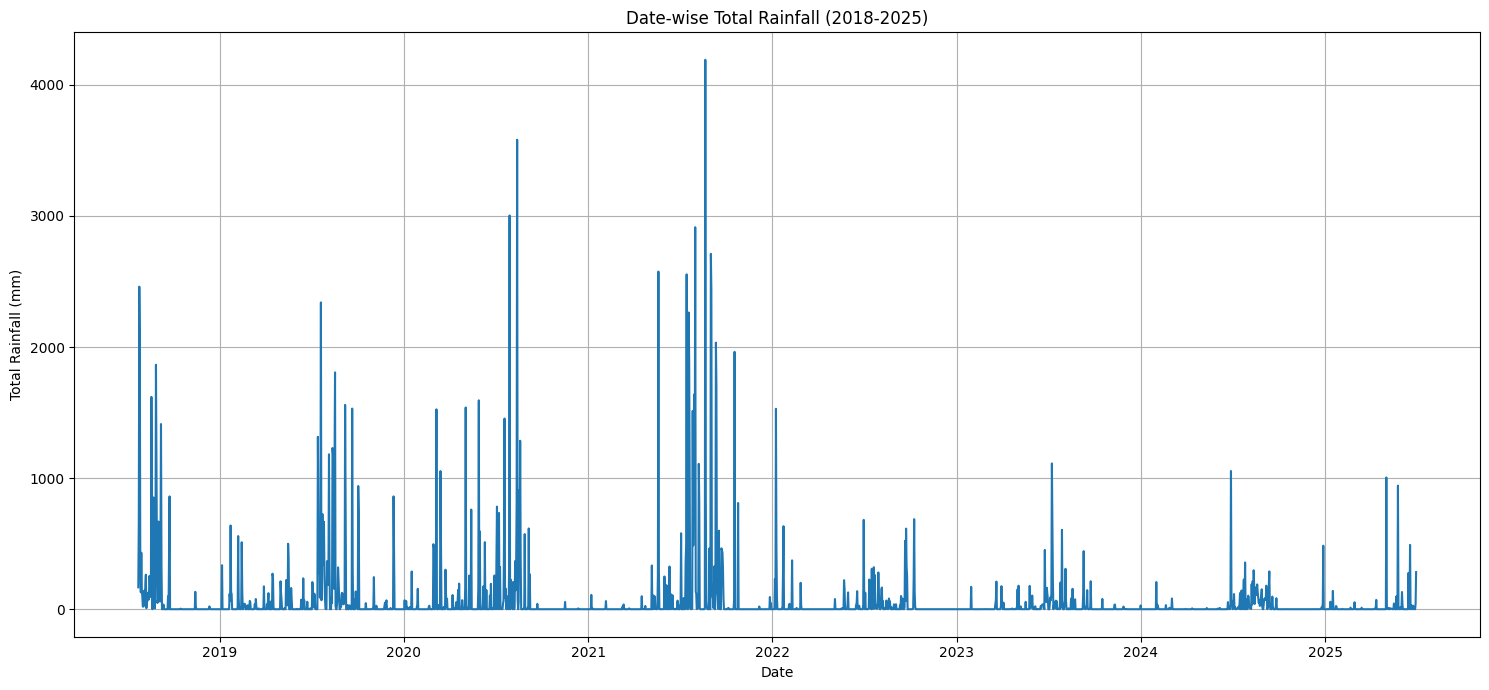

<Figure size 640x480 with 0 Axes>

In [95]:
date_wise_rainfall = df.groupby('Date')['Avg_rainfall'].sum().reset_index(name='Total_Daily_Rainfall')
pd_date_wise_rainfall = date_wise_rainfall

fig2 = plt.figure(figsize=(15, 7))
sns.lineplot(x='Date', y='Total_Daily_Rainfall', data=pd_date_wise_rainfall)
plt.title('Date-wise Total Rainfall (2018-2025)')
plt.xlabel('Date')
plt.ylabel('Total Rainfall (mm)')
plt.grid(True)
plt.tight_layout()
plt.show()
plt.savefig('plots/date_wise_total_rainfall.png')
plt.close(fig2)

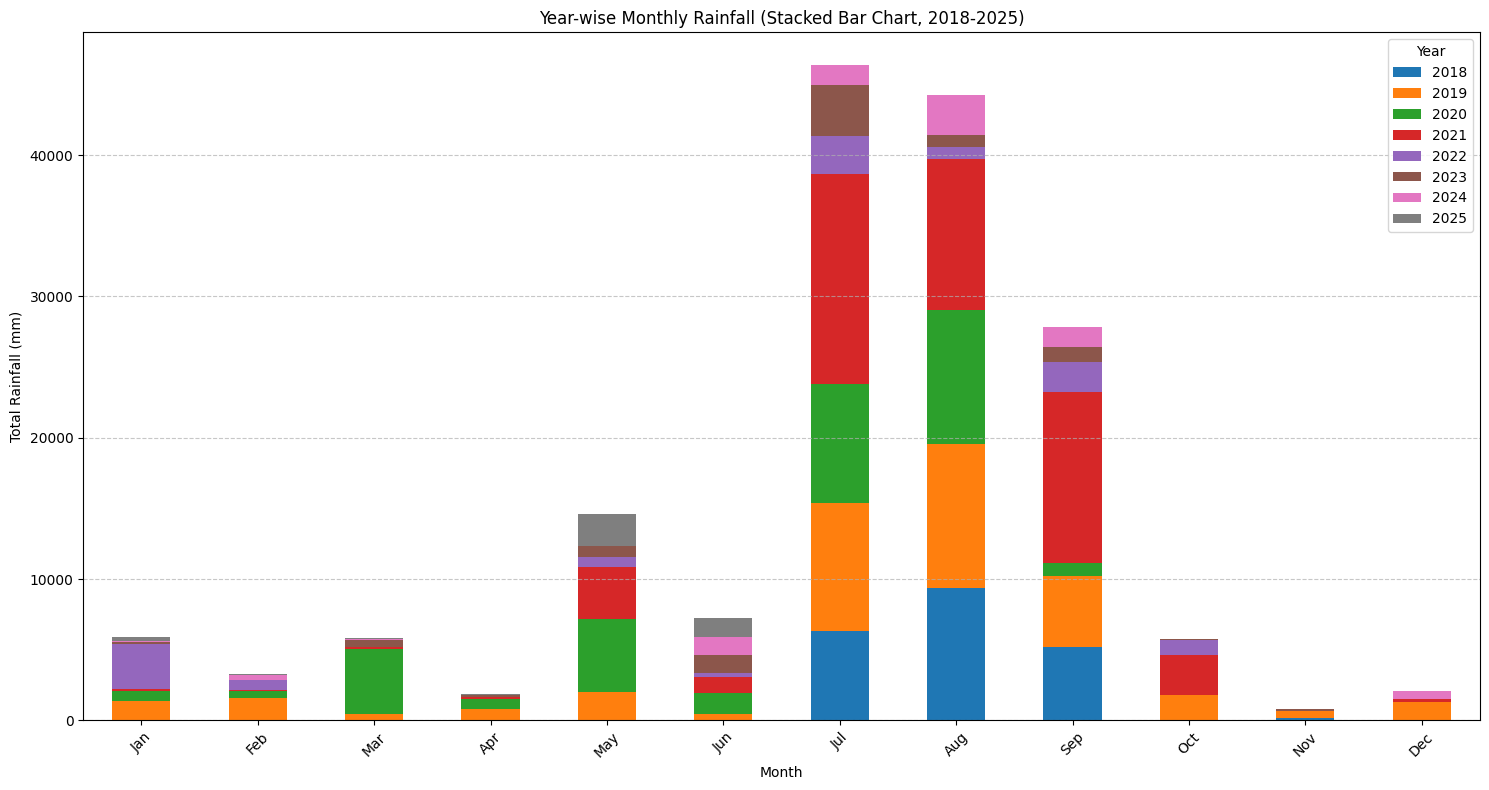

<Figure size 640x480 with 0 Axes>

In [96]:
month_year_wise_rainfall = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')

pd_month_year_wise_rainfall = month_year_wise_rainfall

# Pivot the DataFrame to prepare for stacked bar chart
rainfall_pivot = pd_month_year_wise_rainfall.pivot(index='Month', columns='Year', values='Total_Monthly_Rainfall')

fig3 = plt.figure(figsize=(15, 8))
rainfall_pivot.plot(kind='bar', stacked=True, figsize=(15, 8), ax=fig3.gca()) # Pass ax to plot on the created figure
plt.title('Year-wise Monthly Rainfall (Stacked Bar Chart, 2018-2025)')
plt.xlabel('Month')
plt.ylabel('Total Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Year')
plt.tight_layout()
plt.show()
plt.savefig('plots/year_wise_monthly_rainfall.png')
plt.close(fig3)

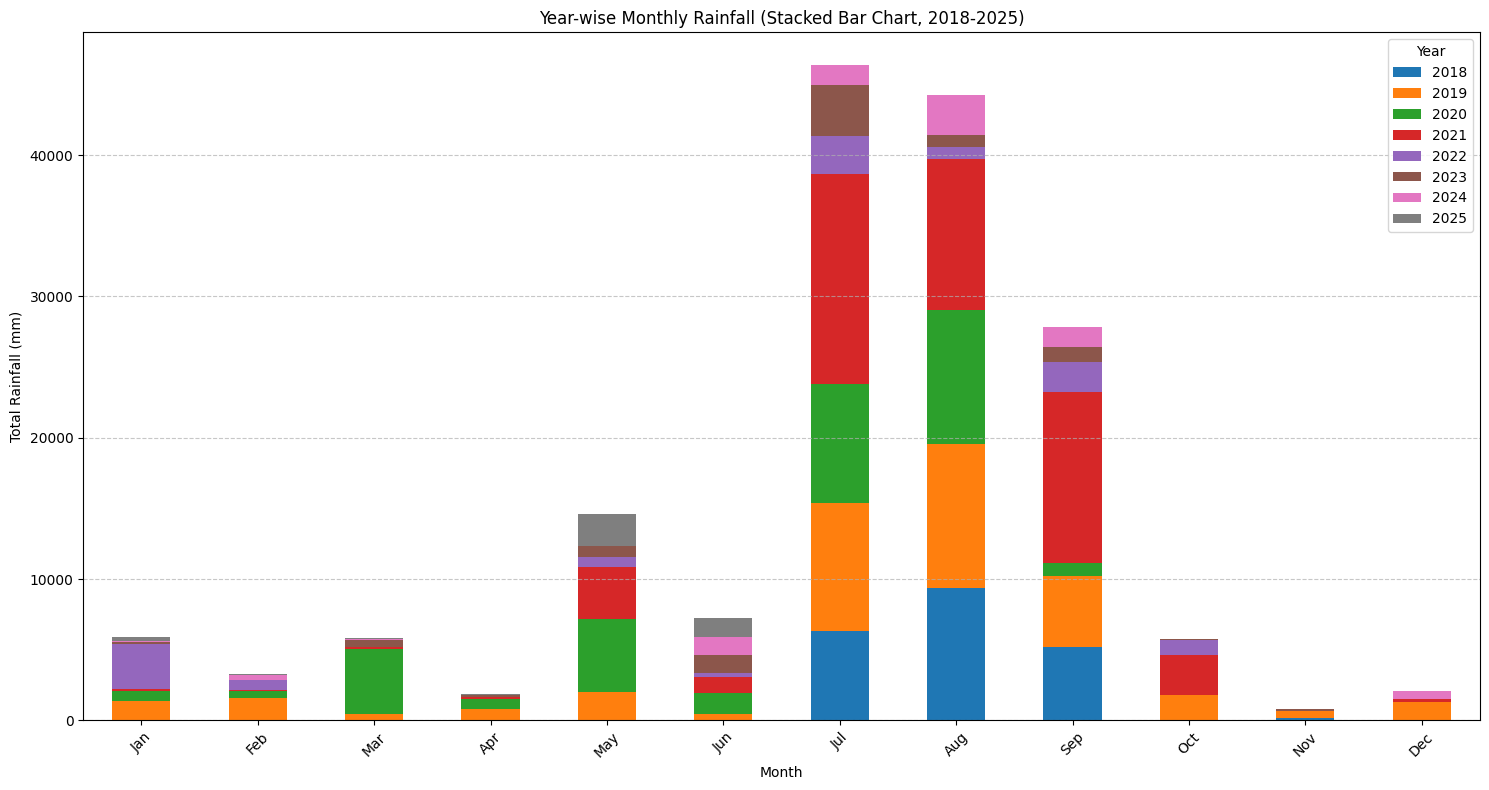

<Figure size 640x480 with 0 Axes>

In [97]:
month_year_wise_rainfall = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
pd_month_year_wise_rainfall = month_year_wise_rainfall

# Pivot the DataFrame to prepare for stacked bar chart
rainfall_pivot = pd_month_year_wise_rainfall.pivot(index='Month', columns='Year', values='Total_Monthly_Rainfall')

fig3 = plt.figure(figsize=(15, 8))
rainfall_pivot.plot(kind='bar', stacked=True, figsize=(15, 8), ax=fig3.gca()) # Pass ax to plot on the created figure
plt.title('Year-wise Monthly Rainfall (Stacked Bar Chart, 2018-2025)')
plt.xlabel('Month')
plt.ylabel('Total Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Year')
plt.tight_layout()
plt.show()
plt.savefig('plots/year_wise_monthly_rainfall.png')
plt.close(fig3)

### 1. Histogram of Average Rainfall Distribution

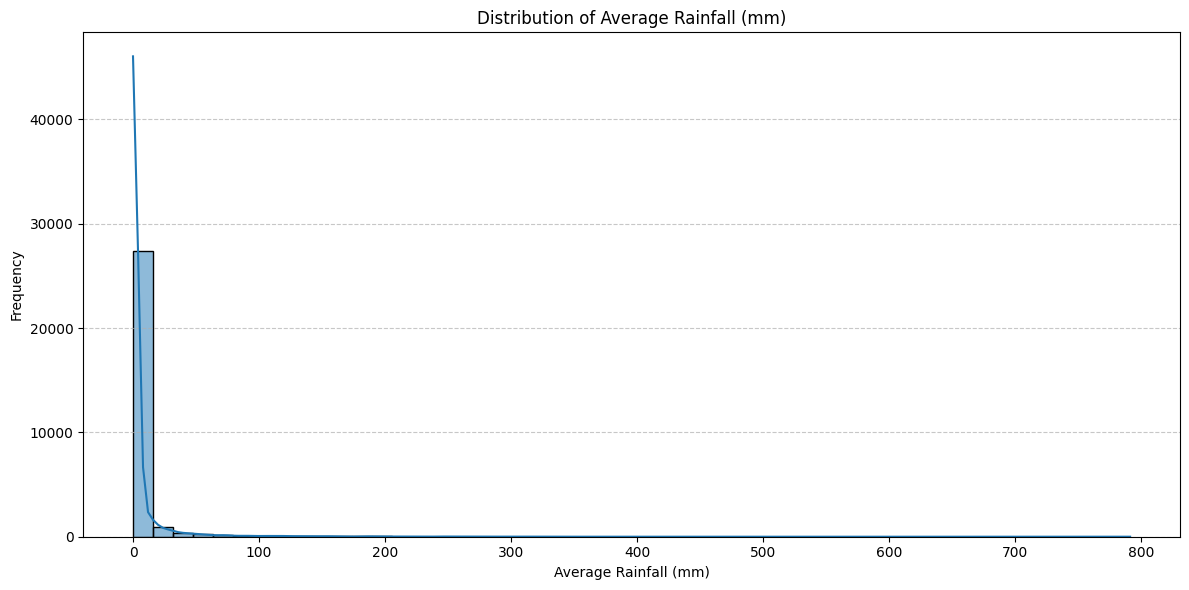

<Figure size 640x480 with 0 Axes>

In [99]:
fig4 = plt.figure(figsize=(12, 6))
sns.histplot(df['Avg_rainfall'].to_numpy(), bins=50, kde=True)
plt.title('Distribution of Average Rainfall (mm)')
plt.xlabel('Average Rainfall (mm)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/distribution_of_average_rainfall.png')
plt.close(fig4)

### 2. Monthly Average Rainfall Bar Chart (Overall)

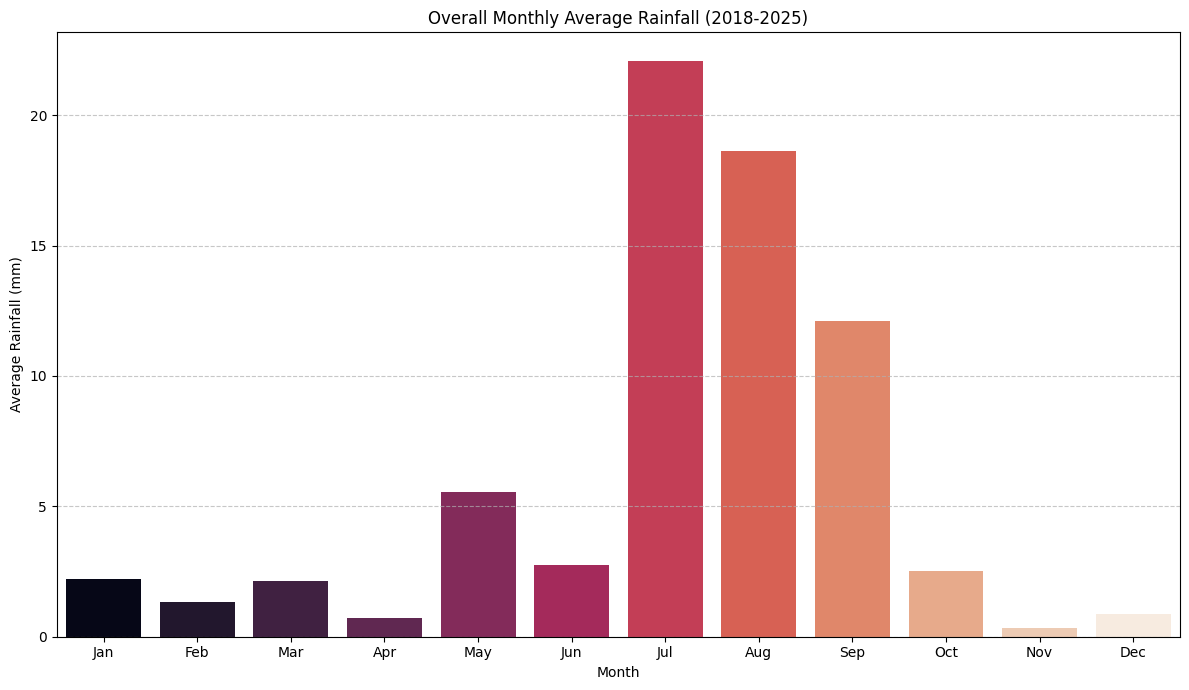

<Figure size 640x480 with 0 Axes>

In [132]:
monthly_avg_rainfall = df.groupby('Month')['Avg_rainfall'].mean().reset_index(name='Average_Rainfall')

pd_monthly_avg_rainfall = monthly_avg_rainfall

fig5 = plt.figure(figsize=(12, 7))
sns.barplot(x='Month', y='Average_Rainfall', data=pd_monthly_avg_rainfall, palette='rocket', hue='Month', legend=False)
plt.title('Overall Monthly Average Rainfall (2018-2025)')
plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/overall_monthly_average_rainfall.png')
plt.close(fig5)

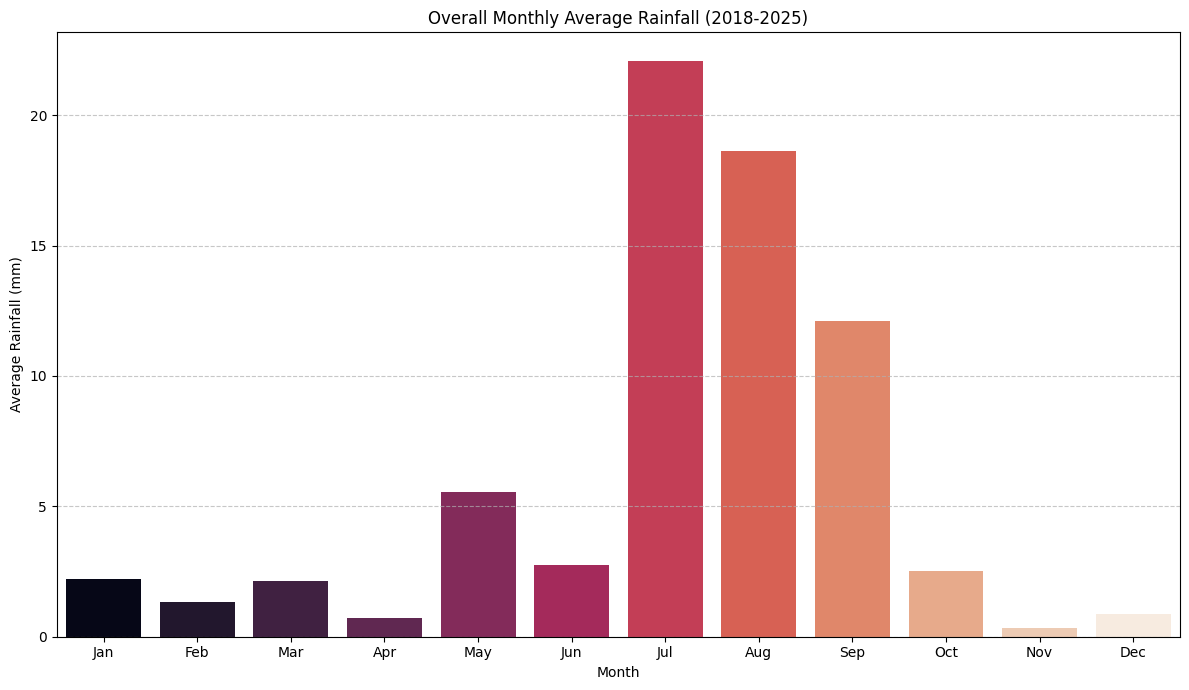

<Figure size 640x480 with 0 Axes>

In [139]:
monthly_avg_rainfall = df.groupby('Month')['Avg_rainfall'].mean().reset_index(name='Average_Rainfall')
pd_monthly_avg_rainfall = monthly_avg_rainfall

fig5 = plt.figure(figsize=(12, 7))
sns.barplot(x='Month', y='Average_Rainfall', data=pd_monthly_avg_rainfall, palette='rocket', hue='Month', legend=False)
plt.title('Overall Monthly Average Rainfall (2018-2025)')
plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/overall_monthly_average_rainfall.png')
plt.close(fig5)

### 3. District-wise Average Rainfall Bar Chart

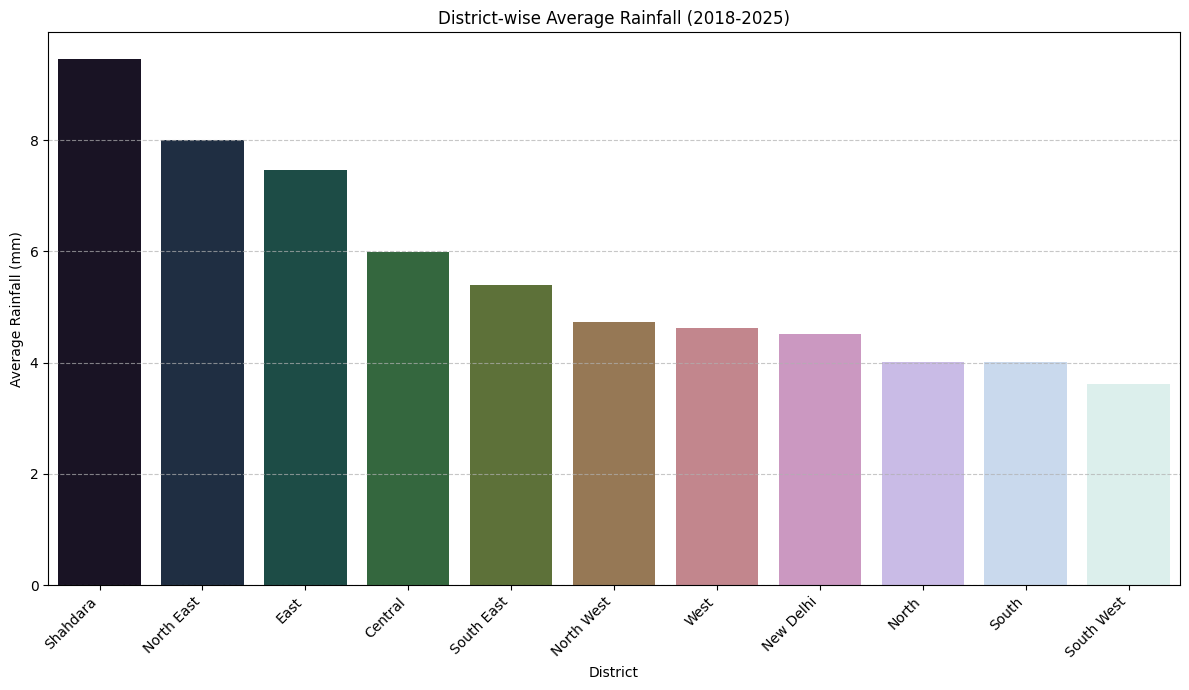

<Figure size 640x480 with 0 Axes>

In [133]:
district_avg_rainfall = df.groupby('District')['Avg_rainfall'].mean().reset_index(name='Average_Rainfall')
district_avg_rainfall = district_avg_rainfall.sort_values(by='Average_Rainfall', ascending=False)
pd_district_avg_rainfall = district_avg_rainfall

fig6 = plt.figure(figsize=(12, 7))
sns.barplot(x='District', y='Average_Rainfall', data=pd_district_avg_rainfall, palette='cubehelix', hue='District', legend=False)
plt.title('District-wise Average Rainfall (2018-2025)')
plt.xlabel('District')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/district_wise_average_rainfall.png')
plt.close(fig6)

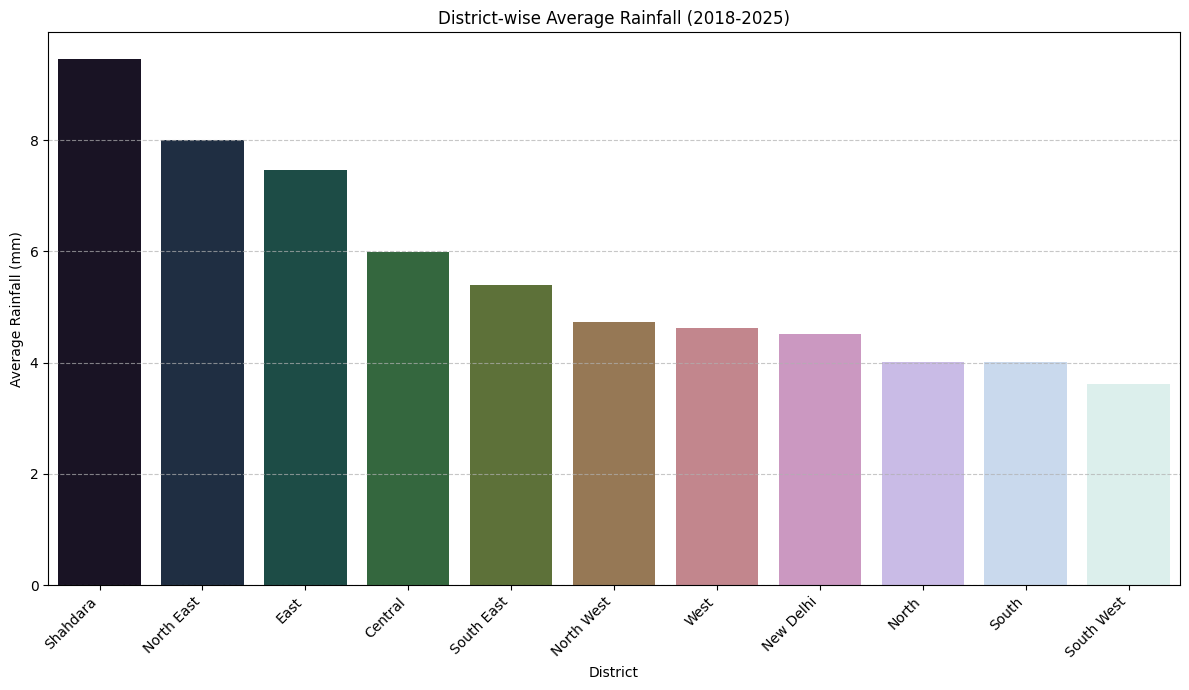

<Figure size 640x480 with 0 Axes>

In [140]:
district_avg_rainfall = df.groupby('District')['Avg_rainfall'].mean().reset_index(name='Average_Rainfall')
district_avg_rainfall = district_avg_rainfall.sort_values(by='Average_Rainfall', ascending=False)
pd_district_avg_rainfall = district_avg_rainfall

fig6 = plt.figure(figsize=(12, 7))
sns.barplot(x='District', y='Average_Rainfall', data=pd_district_avg_rainfall, palette='cubehelix', hue='District', legend=False)
plt.title('District-wise Average Rainfall (2018-2025)')
plt.xlabel('District')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/district_wise_average_rainfall.png')
plt.close(fig6)

### 4. Rainfall Trend by District Over Years (Line Chart)

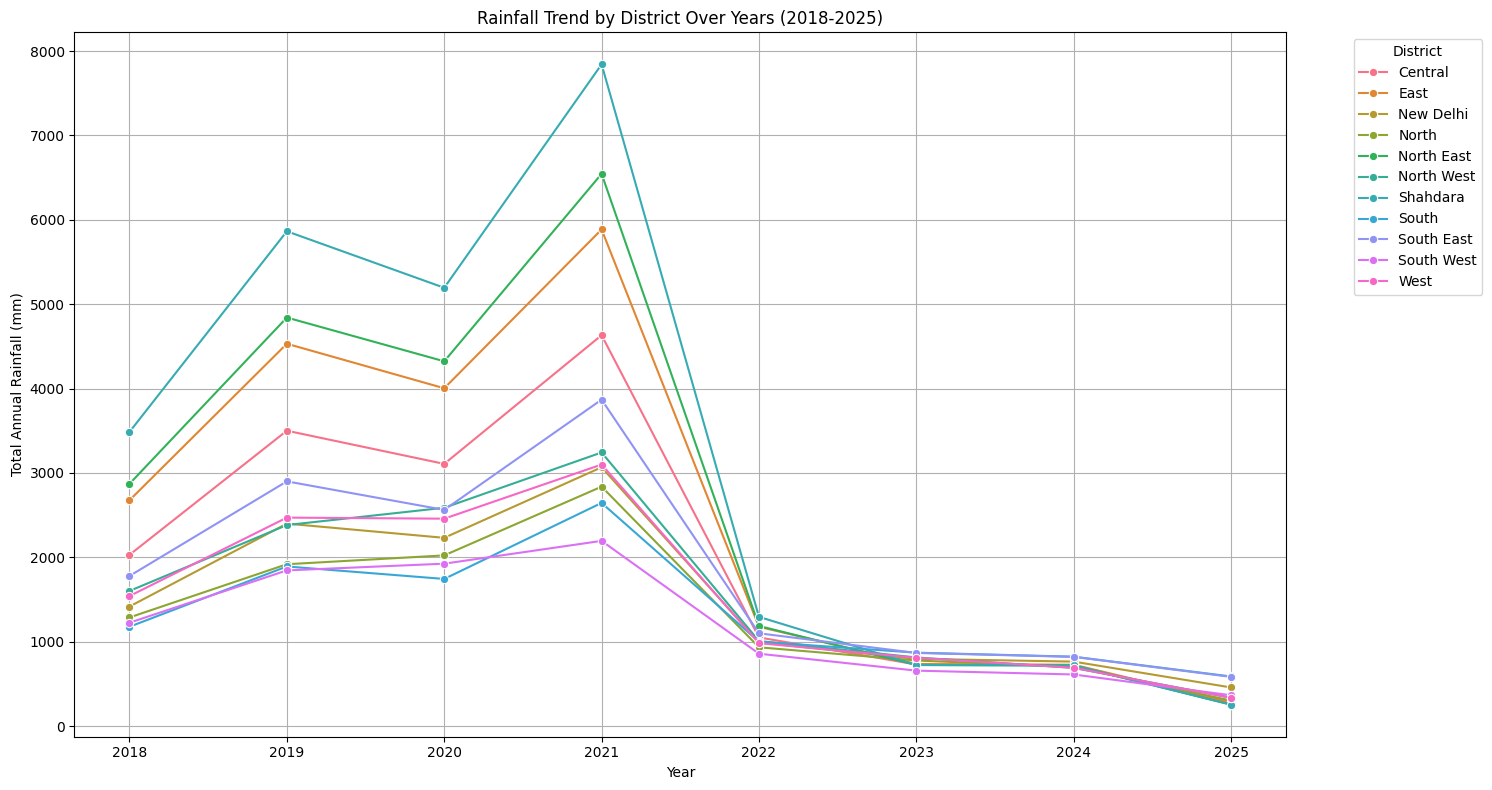

<Figure size 640x480 with 0 Axes>

In [106]:
district_year_rainfall = df.groupby(['Year', 'District'])['Avg_rainfall'].sum().reset_index(name='Total_Annual_Rainfall')
district_year_rainfall = district_year_rainfall.sort_values(by=['Year', 'District'])
pd_district_year_rainfall = district_year_rainfall

fig7 = plt.figure(figsize=(15, 8))
sns.lineplot(x='Year', y='Total_Annual_Rainfall', hue='District', data=pd_district_year_rainfall, marker='o')
plt.title('Rainfall Trend by District Over Years (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Total Annual Rainfall (mm)')
plt.xticks(pd_district_year_rainfall['Year'].unique())
plt.grid(True)
plt.legend(title='District', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.savefig('plots/rainfall_trend_by_district_over_years_1.png')
plt.close(fig7)

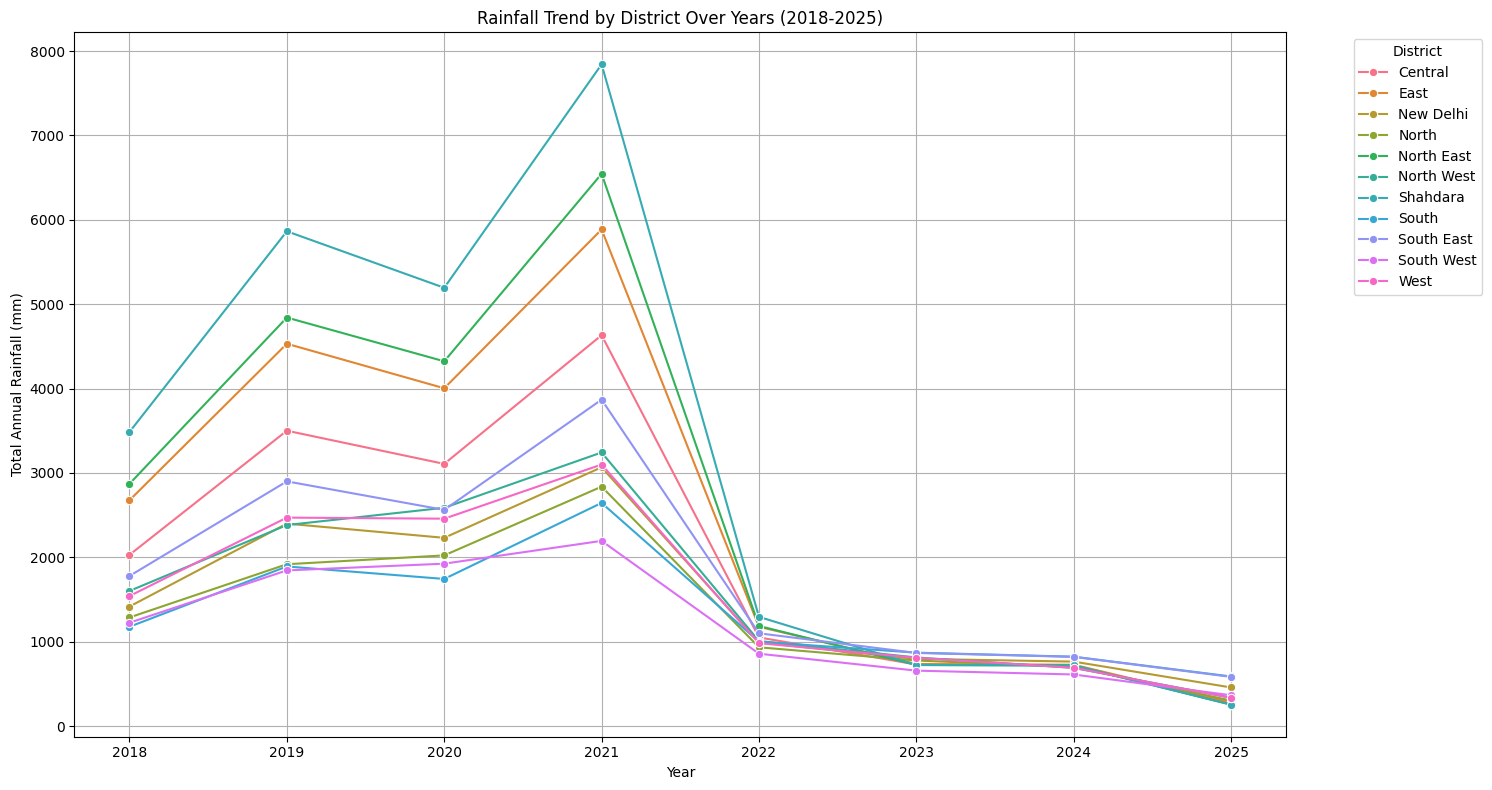

<Figure size 640x480 with 0 Axes>

In [107]:
district_year_rainfall = df.groupby(['Year', 'District'])['Avg_rainfall'].sum().reset_index(name='Total_Annual_Rainfall')
district_year_rainfall = district_year_rainfall.sort_values(by=['Year', 'District'])
pd_district_year_rainfall = district_year_rainfall

fig7 = plt.figure(figsize=(15, 8))
sns.lineplot(x='Year', y='Total_Annual_Rainfall', hue='District', data=pd_district_year_rainfall, marker='o')
plt.title('Rainfall Trend by District Over Years (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Total Annual Rainfall (mm)')
plt.xticks(pd_district_year_rainfall['Year'].unique())
plt.grid(True)
plt.legend(title='District', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.savefig('plots/rainfall_trend_by_district_over_years_1.png')
plt.close(fig7)

### 5. Monthly Rainfall Heatmap by Year

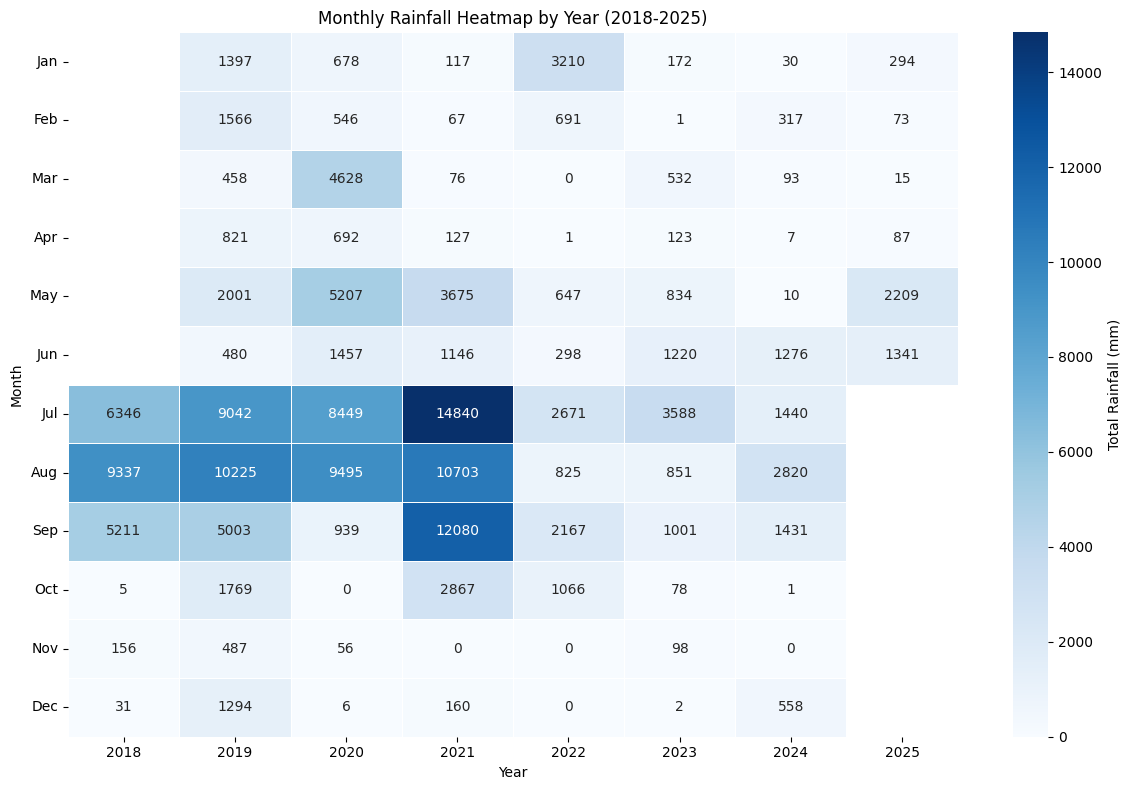

<Figure size 640x480 with 0 Axes>

In [109]:
monthly_total_rainfall = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
monthly_total_rainfall = monthly_total_rainfall.sort_values(by=['Year', 'Month'])
pd_monthly_total_rainfall = monthly_total_rainfall

# Pivot for heatmap: index=Month, columns=Year, values=Total_Monthly_Rainfall
heatmap_data = pd_monthly_total_rainfall.pivot_table(index='Month', columns='Year', values='Total_Monthly_Rainfall')

fig8 = plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap='Blues', annot=True, fmt='.0f', linewidths=.5, cbar_kws={'label': 'Total Rainfall (mm)'})
plt.title('Monthly Rainfall Heatmap by Year (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Month')
plt.yticks(ticks=np.arange(0.5, 12.5, 1), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('plots/monthly_rainfall_heatmap_by_year_1.png')
plt.close(fig8)

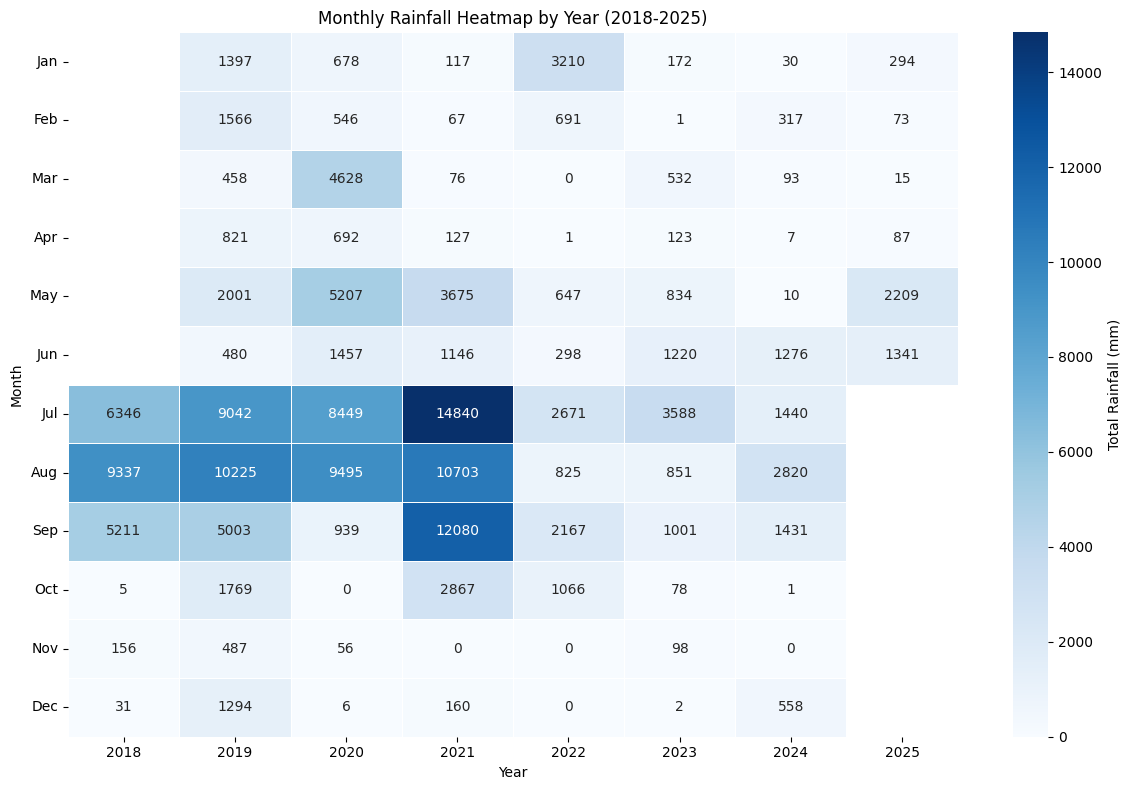

<Figure size 640x480 with 0 Axes>

In [110]:
monthly_total_rainfall = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
monthly_total_rainfall = monthly_total_rainfall.sort_values(by=['Year', 'Month'])
pd_monthly_total_rainfall = monthly_total_rainfall

# Pivot for heatmap: index=Month, columns=Year, values=Total_Monthly_Rainfall
heatmap_data = pd_monthly_total_rainfall.pivot_table(index='Month', columns='Year', values='Total_Monthly_Rainfall')

fig8 = plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap='Blues', annot=True, fmt='.0f', linewidths=.5, cbar_kws={'label': 'Total Rainfall (mm)'})
plt.title('Monthly Rainfall Heatmap by Year (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Month')
plt.yticks(ticks=np.arange(0.5, 12.5, 1), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('plots/monthly_rainfall_heatmap_by_year_1.png')
plt.close(fig8)

### 4. Rainfall Trend by District Over Years (Line Chart)

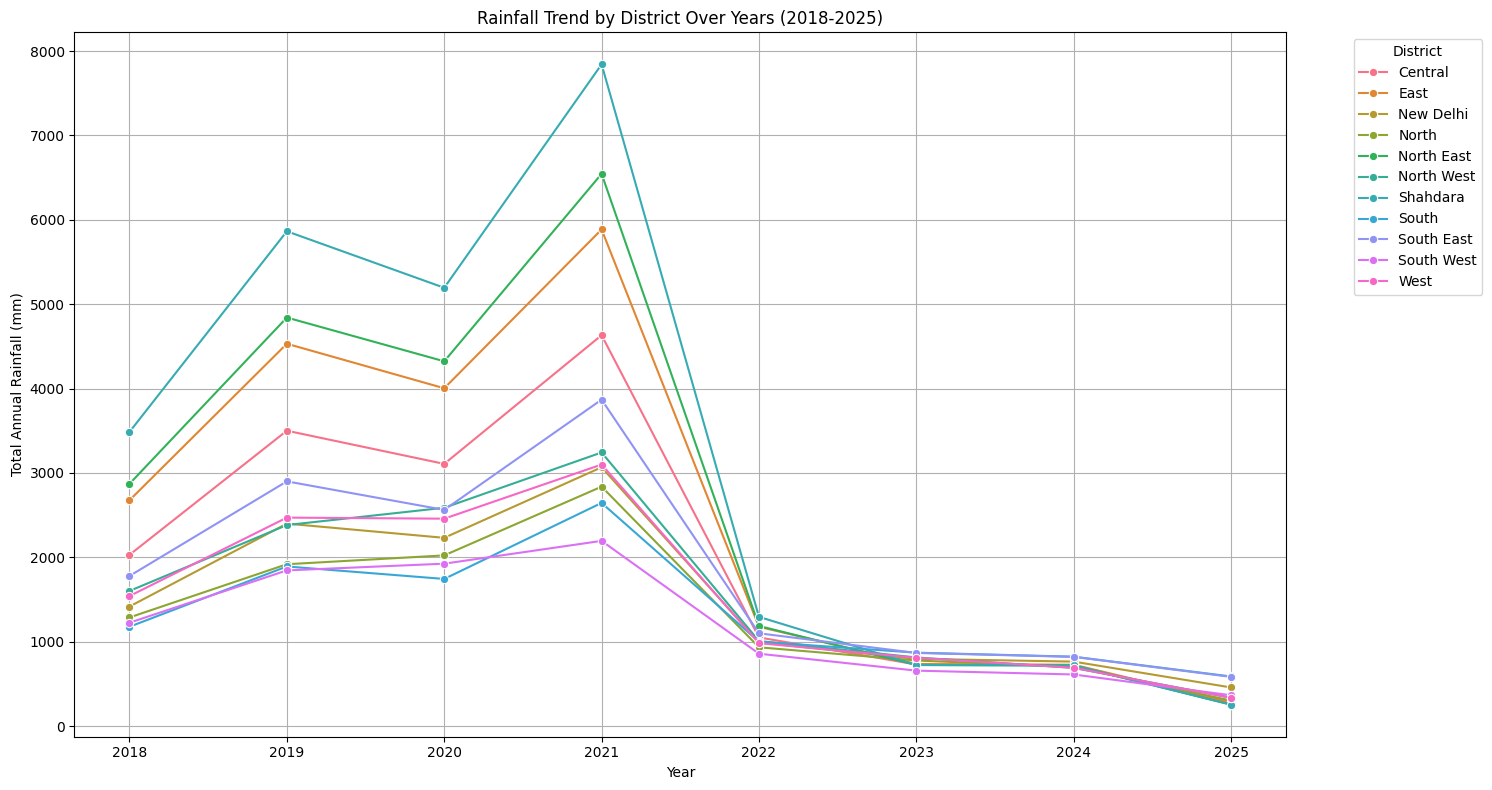

<Figure size 640x480 with 0 Axes>

In [111]:
district_year_rainfall = df.groupby(['Year', 'District'])['Avg_rainfall'].sum().reset_index(name='Total_Annual_Rainfall')
district_year_rainfall = district_year_rainfall.sort_values(by=['Year', 'District'])
pd_district_year_rainfall = district_year_rainfall

fig9 = plt.figure(figsize=(15, 8))
sns.lineplot(x='Year', y='Total_Annual_Rainfall', hue='District', data=pd_district_year_rainfall, marker='o')
plt.title('Rainfall Trend by District Over Years (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Total Annual Rainfall (mm)')
plt.xticks(pd_district_year_rainfall['Year'].unique())
plt.grid(True)
plt.legend(title='District', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.savefig('plots/rainfall_trend_by_district_over_years_2.png')
plt.close(fig9)

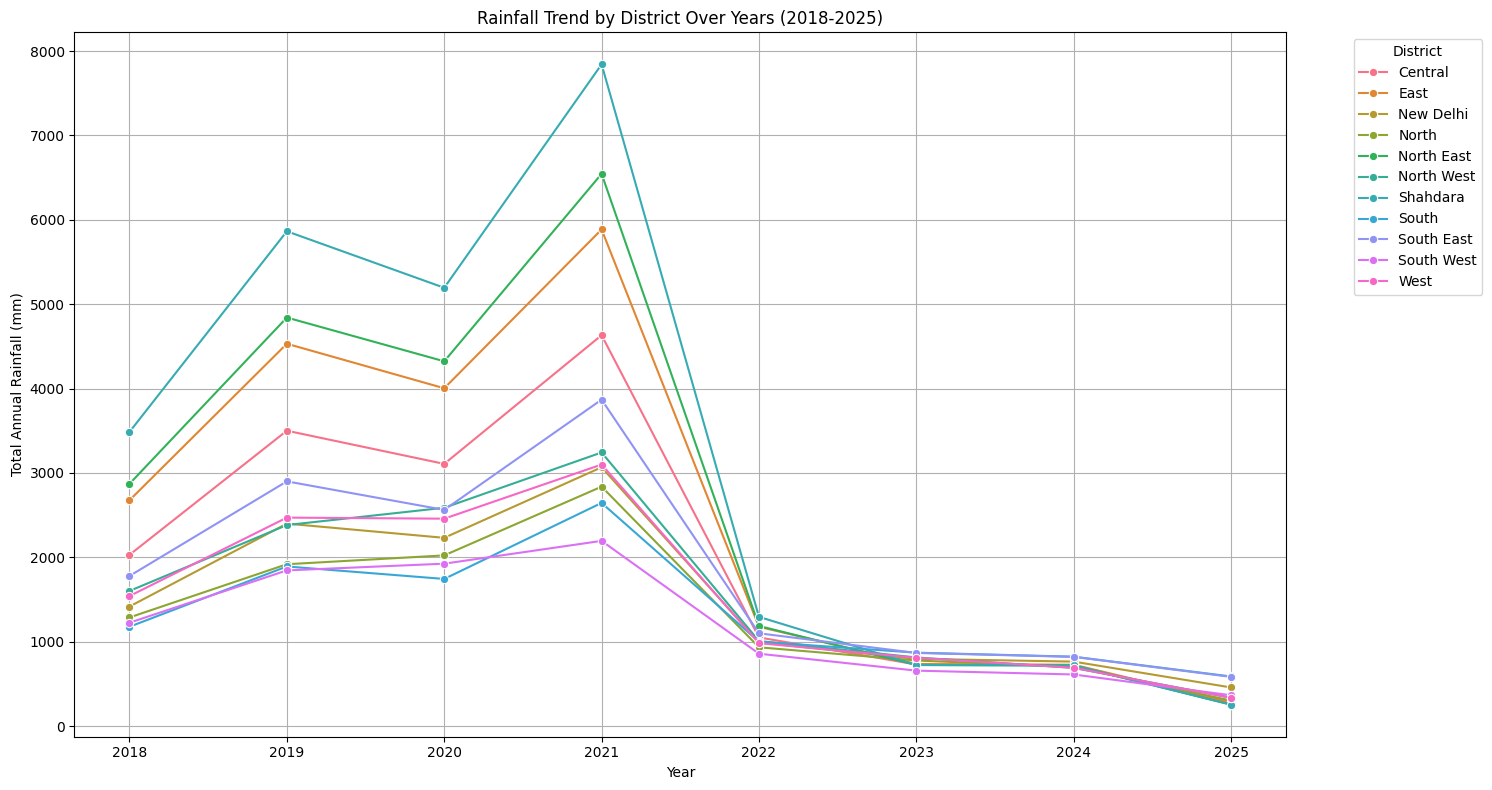

<Figure size 640x480 with 0 Axes>

In [113]:
district_year_rainfall = df.groupby(['Year', 'District'])['Avg_rainfall'].sum().reset_index(name='Total_Annual_Rainfall')
district_year_rainfall = district_year_rainfall.sort_values(by=['Year', 'District'])
pd_district_year_rainfall = district_year_rainfall

fig9 = plt.figure(figsize=(15, 8))
sns.lineplot(x='Year', y='Total_Annual_Rainfall', hue='District', data=pd_district_year_rainfall, marker='o')
plt.title('Rainfall Trend by District Over Years (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Total Annual Rainfall (mm)')
plt.xticks(pd_district_year_rainfall['Year'].unique())
plt.grid(True)
plt.legend(title='District', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.savefig('plots/rainfall_trend_by_district_over_years_2.png')
plt.close(fig9)

### 5. Monthly Rainfall Heatmap by Year

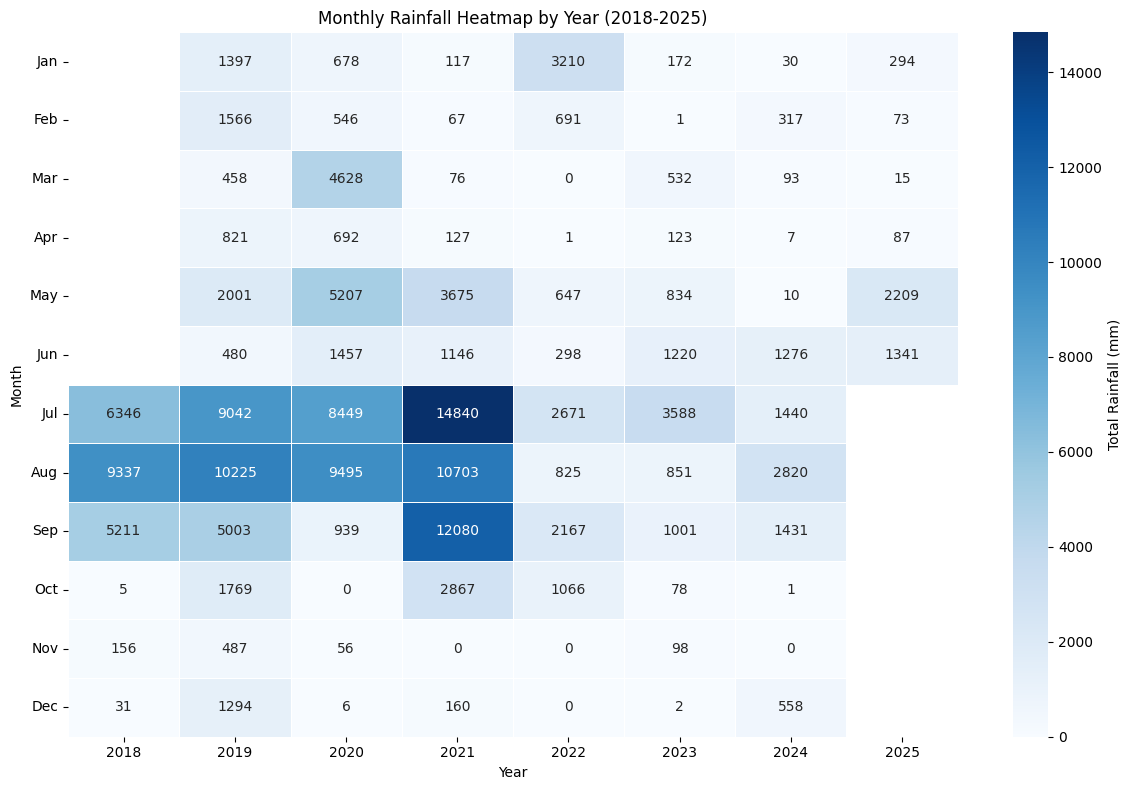

<Figure size 640x480 with 0 Axes>

In [114]:
monthly_total_rainfall = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
monthly_total_rainfall = monthly_total_rainfall.sort_values(by=['Year', 'Month'])
pd_monthly_total_rainfall = monthly_total_rainfall

# Pivot for heatmap: index=Month, columns=Year, values=Total_Monthly_Rainfall
heatmap_data = pd_monthly_total_rainfall.pivot_table(index='Month', columns='Year', values='Total_Monthly_Rainfall')

fig10 = plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap='Blues', annot=True, fmt='.0f', linewidths=.5, cbar_kws={'label': 'Total Rainfall (mm)'})
plt.title('Monthly Rainfall Heatmap by Year (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Month')
plt.yticks(ticks=np.arange(0.5, 12.5, 1), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('plots/monthly_rainfall_heatmap_by_year_2.png')
plt.close(fig10)

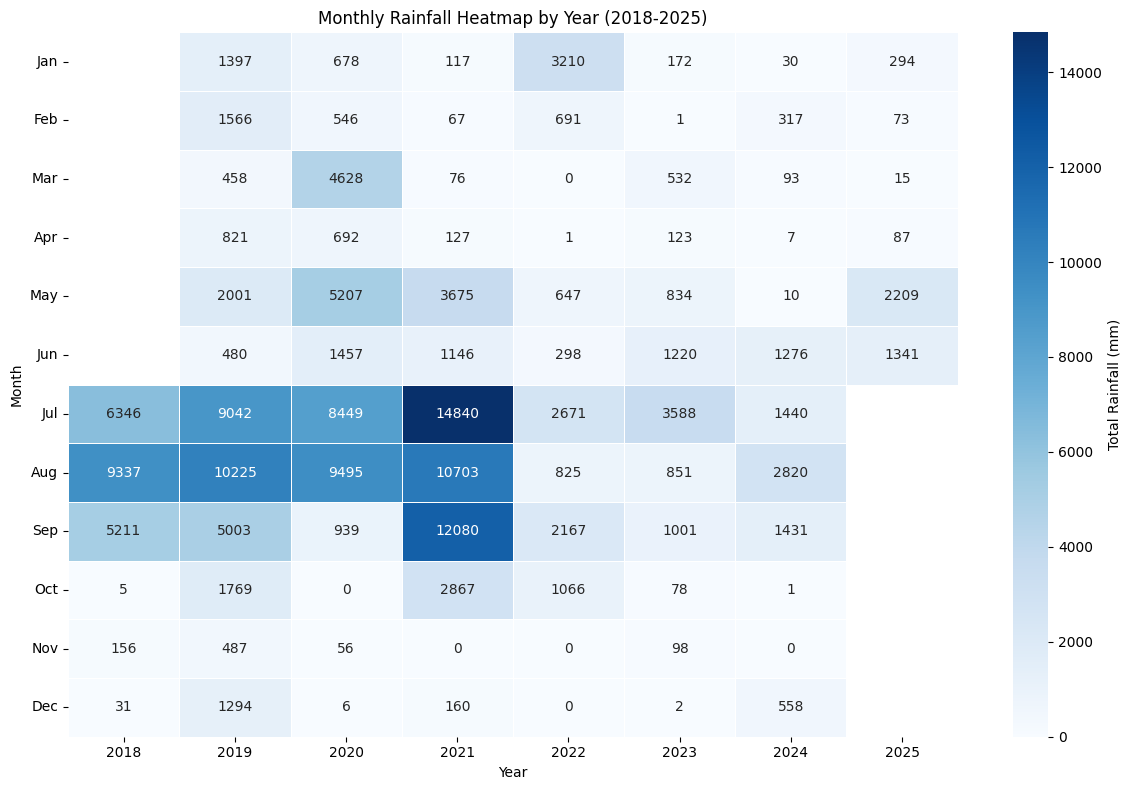

<Figure size 640x480 with 0 Axes>

In [115]:
monthly_total_rainfall = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
monthly_total_rainfall = monthly_total_rainfall.sort_values(by=['Year', 'Month'])
pd_monthly_total_rainfall = monthly_total_rainfall

# Pivot for heatmap: index=Month, columns=Year, values=Total_Monthly_Rainfall
heatmap_data = pd_monthly_total_rainfall.pivot_table(index='Month', columns='Year', values='Total_Monthly_Rainfall')

fig10 = plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap='Blues', annot=True, fmt='.0f', linewidths=.5, cbar_kws={'label': 'Total Rainfall (mm)'})
plt.title('Monthly Rainfall Heatmap by Year (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Month')
plt.yticks(ticks=np.arange(0.5, 12.5, 1), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('plots/monthly_rainfall_heatmap_by_year_2.png')
plt.close(fig10)

### 6. Monthly Rainfall Distribution Across Years (Box Plot)

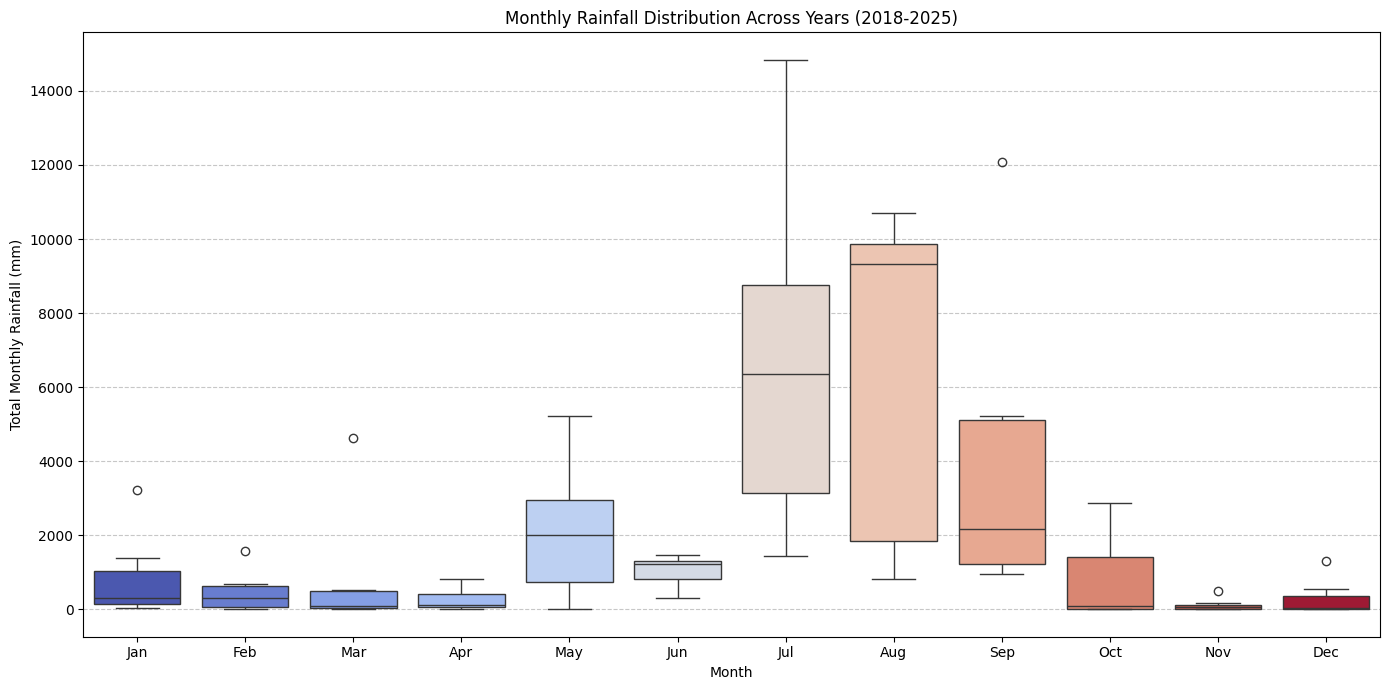

<Figure size 640x480 with 0 Axes>

In [116]:
monthly_total_rainfall_all_years = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
monthly_total_rainfall_all_years = monthly_total_rainfall_all_years.sort_values(by=['Year', 'Month'])
pd_monthly_total_rainfall_all_years = monthly_total_rainfall_all_years

fig11 = plt.figure(figsize=(14, 7))
sns.boxplot(x='Month', y='Total_Monthly_Rainfall', data=pd_monthly_total_rainfall_all_years, palette='coolwarm', hue='Month', legend=False)
plt.title('Monthly Rainfall Distribution Across Years (2018-2025)')
plt.xlabel('Month')
plt.ylabel('Total Monthly Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/monthly_rainfall_distribution_across_years.png')
plt.close(fig11)

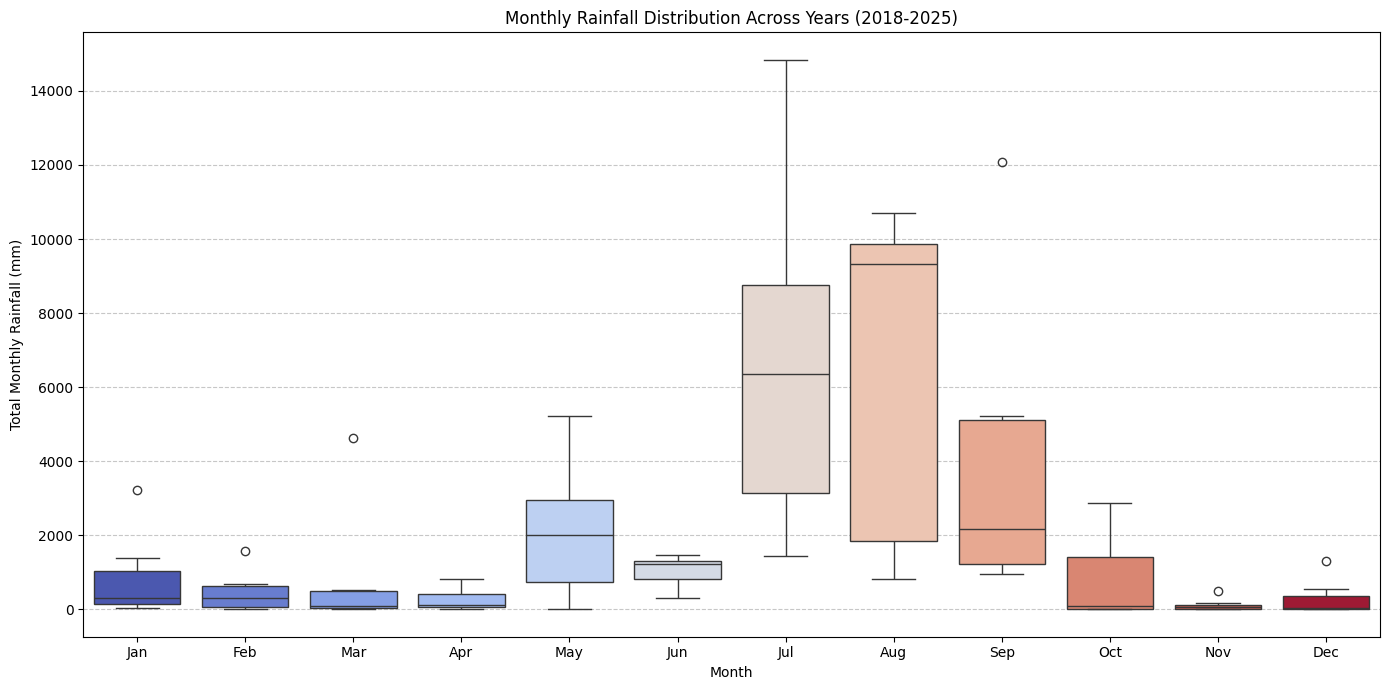

<Figure size 640x480 with 0 Axes>

In [117]:
monthly_total_rainfall_all_years = df.groupby(['Year', 'Month'])['Avg_rainfall'].sum().reset_index(name='Total_Monthly_Rainfall')
monthly_total_rainfall_all_years = monthly_total_rainfall_all_years.sort_values(by=['Year', 'Month'])
pd_monthly_total_rainfall_all_years = monthly_total_rainfall_all_years

fig11 = plt.figure(figsize=(14, 7))
sns.boxplot(x='Month', y='Total_Monthly_Rainfall', data=pd_monthly_total_rainfall_all_years, palette='coolwarm', hue='Month', legend=False)
plt.title('Monthly Rainfall Distribution Across Years (2018-2025)')
plt.xlabel('Month')
plt.ylabel('Total Monthly Rainfall (mm)')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
plt.savefig('plots/monthly_rainfall_distribution_across_years.png')
plt.close(fig11)

### 7. Daily Rainfall Anomaly Heatmap

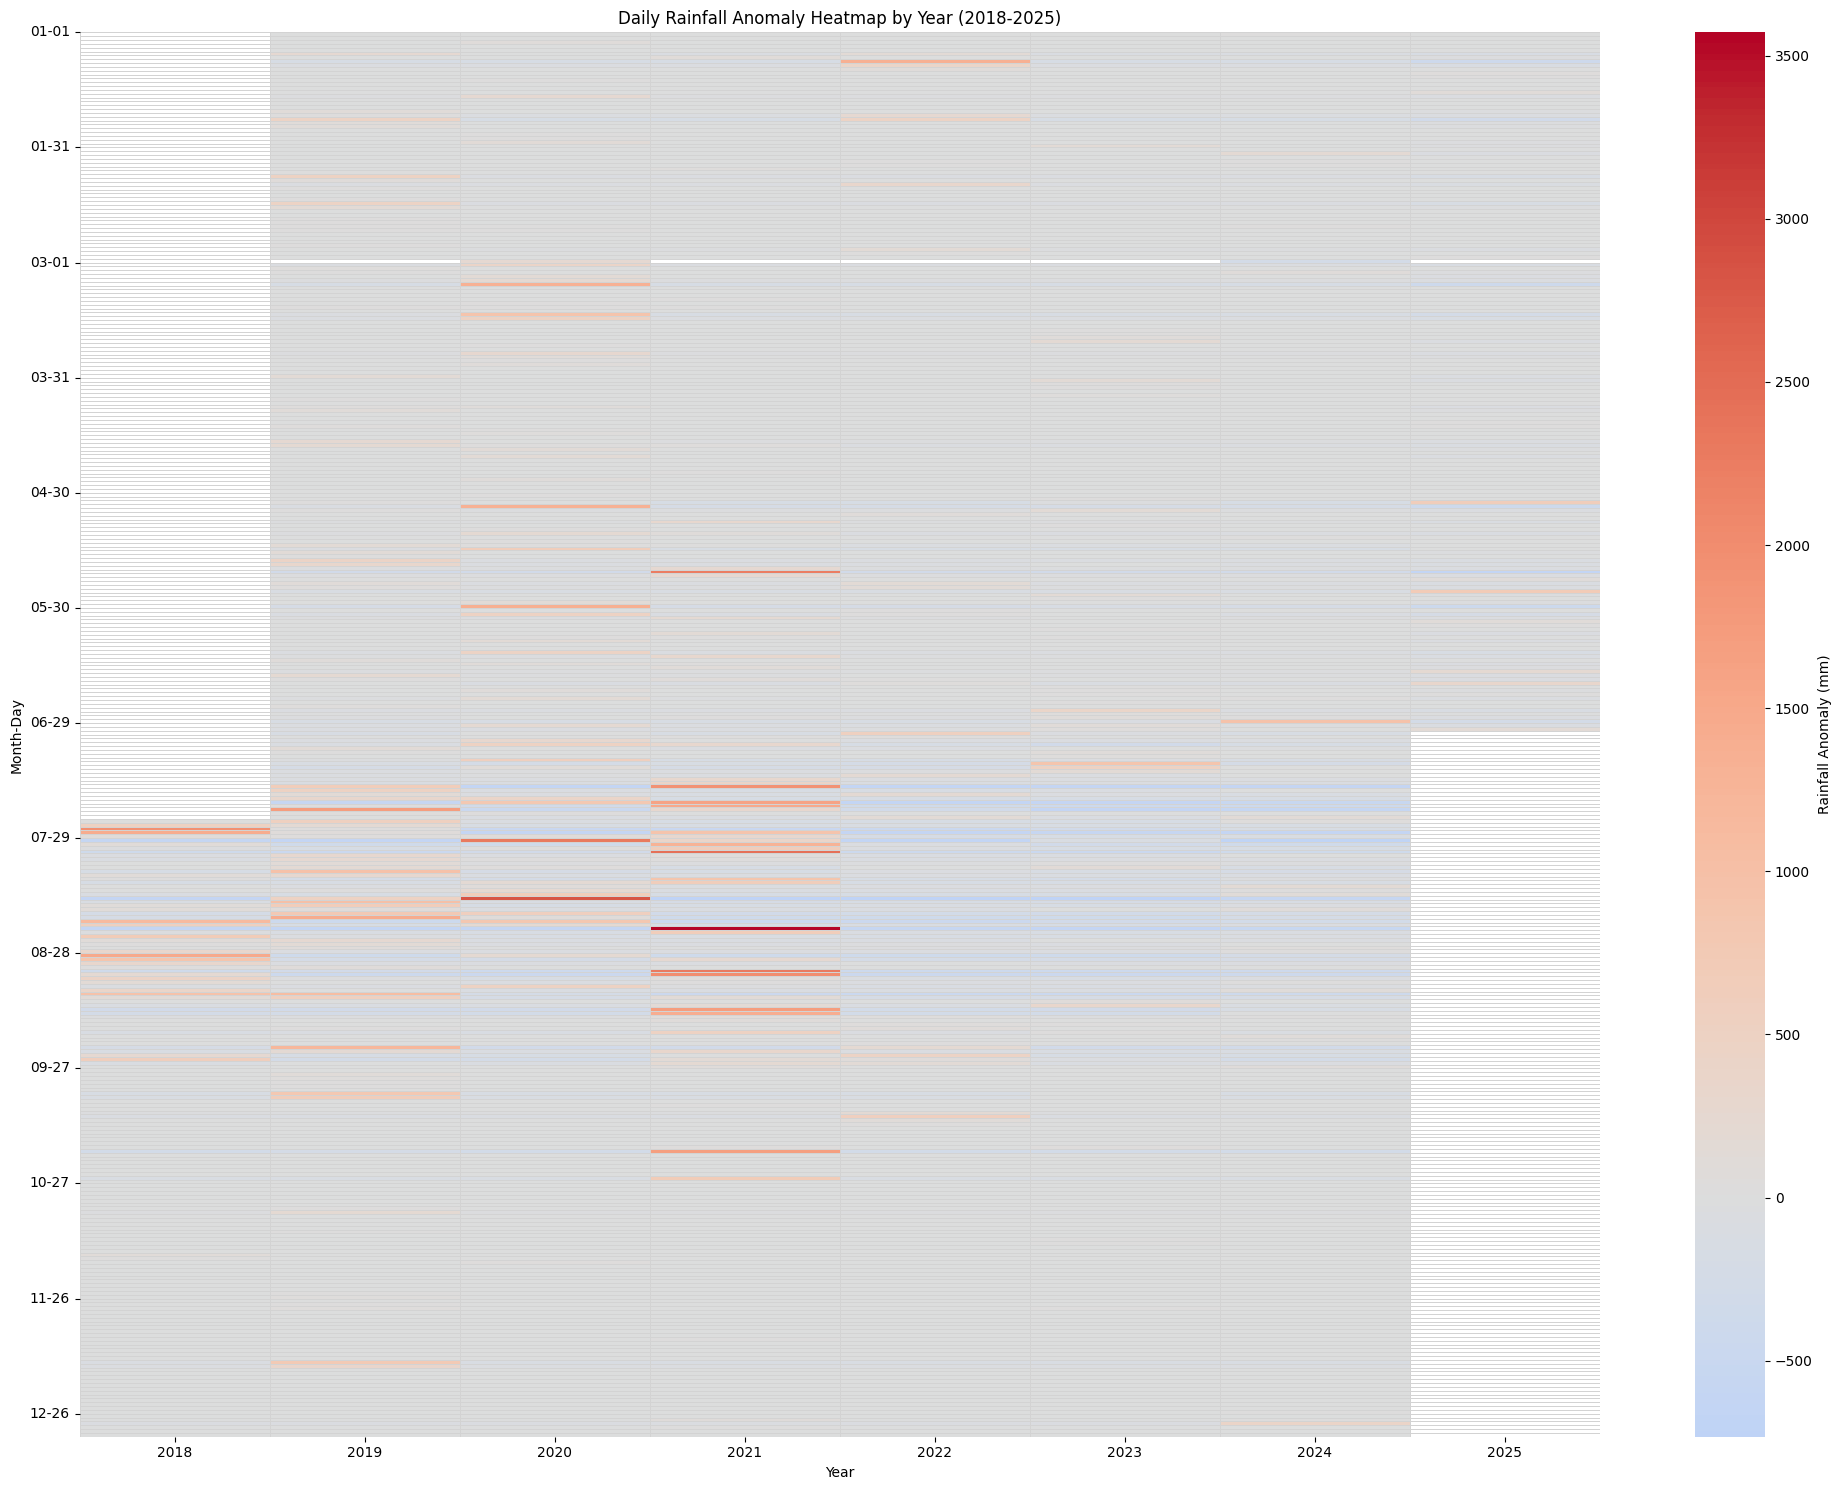

<Figure size 640x480 with 0 Axes>

In [118]:
import pandas as pd
# Calculate daily average rainfall across all years for each day of the year
df_avg_daily_seasonal = df.groupby(['Month', 'Day'])['Avg_rainfall'].mean().reset_index(name='Daily_Average_Rainfall')

# Join the average daily rainfall back to the original DataFrame
df_with_anomaly = pd.merge(df, df_avg_daily_seasonal, on=['Month', 'Day'], how='left')

# Calculate Rainfall_Anomaly
df_with_anomaly['Rainfall_Anomaly'] = df_with_anomaly['Avg_rainfall'] - df_with_anomaly['Daily_Average_Rainfall']

# Prepare data for heatmap - pivot to Year vs Day, values are anomalies
pd_anomaly = df_with_anomaly.groupby(['Year', 'Month', 'Day'])['Rainfall_Anomaly'].sum().reset_index(name='Total_Daily_Anomaly')
pd_anomaly = pd_anomaly.sort_values(by=['Year', 'Month', 'Day'])

pd_anomaly['Date_for_plot'] = pd.to_datetime(pd_anomaly[['Year', 'Month', 'Day']])

# Create a full date range for all years to ensure all days are represented in the heatmap
min_date = pd_anomaly['Date_for_plot'].min()
max_date = pd_anomaly['Date_for_plot'].max()
full_date_range = pd.date_range(start=min_date, end=max_date, freq='D')

# Create a DataFrame with the full date range
full_df = pd.DataFrame({'Date_for_plot': full_date_range})
full_df['Year'] = full_df['Date_for_plot'].dt.year
full_df['Month_Day'] = full_df['Date_for_plot'].dt.strftime('%m-%d')

# Merge with anomaly data
heatmap_data_daily = pd.merge(full_df, pd_anomaly, on='Date_for_plot', how='left')
heatmap_data_daily['Total_Daily_Anomaly'] = heatmap_data_daily['Total_Daily_Anomaly'].fillna(0) # Fill NaN anomalies with 0

# Pivot for heatmap: index=Month_Day, columns=Year_x, values=Total_Daily_Anomaly
anomaly_pivot = heatmap_data_daily.pivot_table(index='Month_Day', columns='Year_x', values='Total_Daily_Anomaly')

fig12 = plt.figure(figsize=(20, 15))
sns.heatmap(anomaly_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Rainfall Anomaly (mm)'}, linewidths=0.5, linecolor='lightgray')
plt.title('Daily Rainfall Anomaly Heatmap by Year (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Month-Day')
plt.yticks(np.arange(0, len(anomaly_pivot.index), 30), anomaly_pivot.index[np.arange(0, len(anomaly_pivot.index), 30)], rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('plots/daily_rainfall_anomaly_heatmap.png')
plt.close(fig12)

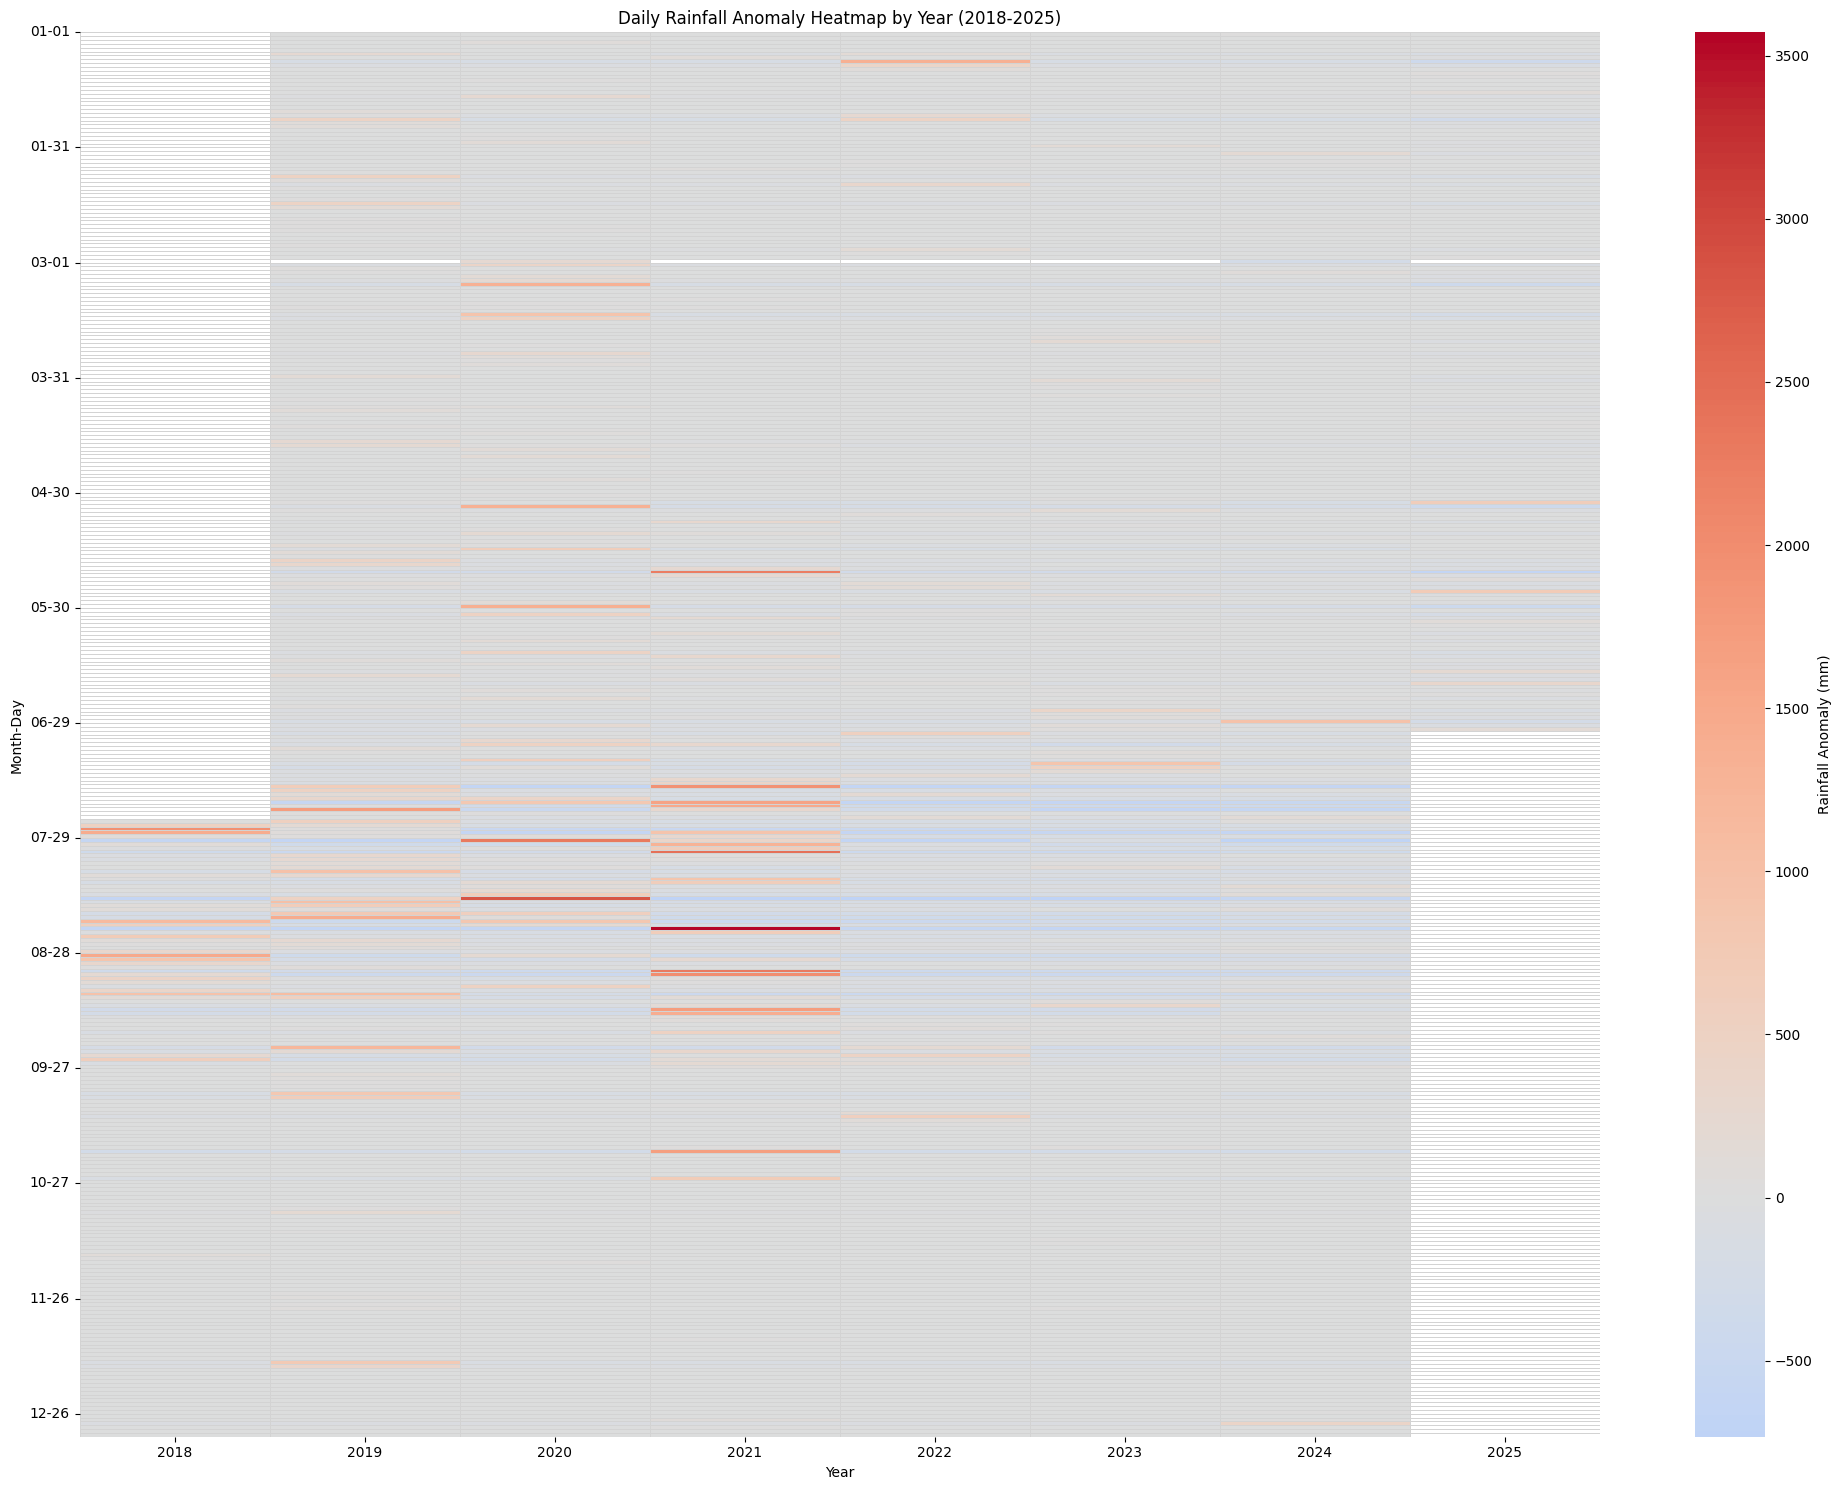

<Figure size 640x480 with 0 Axes>

In [119]:
import pandas as pd
# Calculate daily average rainfall across all years for each day of the year
df_avg_daily_seasonal = df.groupby(['Month', 'Day'])['Avg_rainfall'].mean().reset_index(name='Daily_Average_Rainfall')

# Join the average daily rainfall back to the original DataFrame
df_with_anomaly = pd.merge(df, df_avg_daily_seasonal, on=['Month', 'Day'], how='left')

# Calculate Rainfall_Anomaly
df_with_anomaly['Rainfall_Anomaly'] = df_with_anomaly['Avg_rainfall'] - df_with_anomaly['Daily_Average_Rainfall']

# Prepare data for heatmap - pivot to Year vs Day, values are anomalies
pd_anomaly = df_with_anomaly.groupby(['Year', 'Month', 'Day'])['Rainfall_Anomaly'].sum().reset_index(name='Total_Daily_Anomaly')
pd_anomaly = pd_anomaly.sort_values(by=['Year', 'Month', 'Day'])

pd_anomaly['Date_for_plot'] = pd.to_datetime(pd_anomaly[['Year', 'Month', 'Day']])

# Create a full date range for all years to ensure all days are represented in the heatmap
min_date = pd_anomaly['Date_for_plot'].min()
max_date = pd_anomaly['Date_for_plot'].max()
full_date_range = pd.date_range(start=min_date, end=max_date, freq='D')

# Create a DataFrame with the full date range
full_df = pd.DataFrame({'Date_for_plot': full_date_range})
full_df['Year'] = full_df['Date_for_plot'].dt.year
full_df['Month_Day'] = full_df['Date_for_plot'].dt.strftime('%m-%d')

# Merge with anomaly data
heatmap_data_daily = pd.merge(full_df, pd_anomaly, on='Date_for_plot', how='left')
heatmap_data_daily['Total_Daily_Anomaly'] = heatmap_data_daily['Total_Daily_Anomaly'].fillna(0) # Fill NaN anomalies with 0

# Pivot for heatmap: index=Month_Day, columns=Year_x, values=Total_Daily_Anomaly
anomaly_pivot = heatmap_data_daily.pivot_table(index='Month_Day', columns='Year_x', values='Total_Daily_Anomaly')

fig12 = plt.figure(figsize=(20, 15))
sns.heatmap(anomaly_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Rainfall Anomaly (mm)'}, linewidths=0.5, linecolor='lightgray')
plt.title('Daily Rainfall Anomaly Heatmap by Year (2018-2025)')
plt.xlabel('Year')
plt.ylabel('Month-Day')
plt.yticks(np.arange(0, len(anomaly_pivot.index), 30), anomaly_pivot.index[np.arange(0, len(anomaly_pivot.index), 30)], rotation=0)
plt.tight_layout()
plt.show()
plt.savefig('plots/daily_rainfall_anomaly_heatmap.png')
plt.close(fig12)

### 8. Rainfall Duration Curve

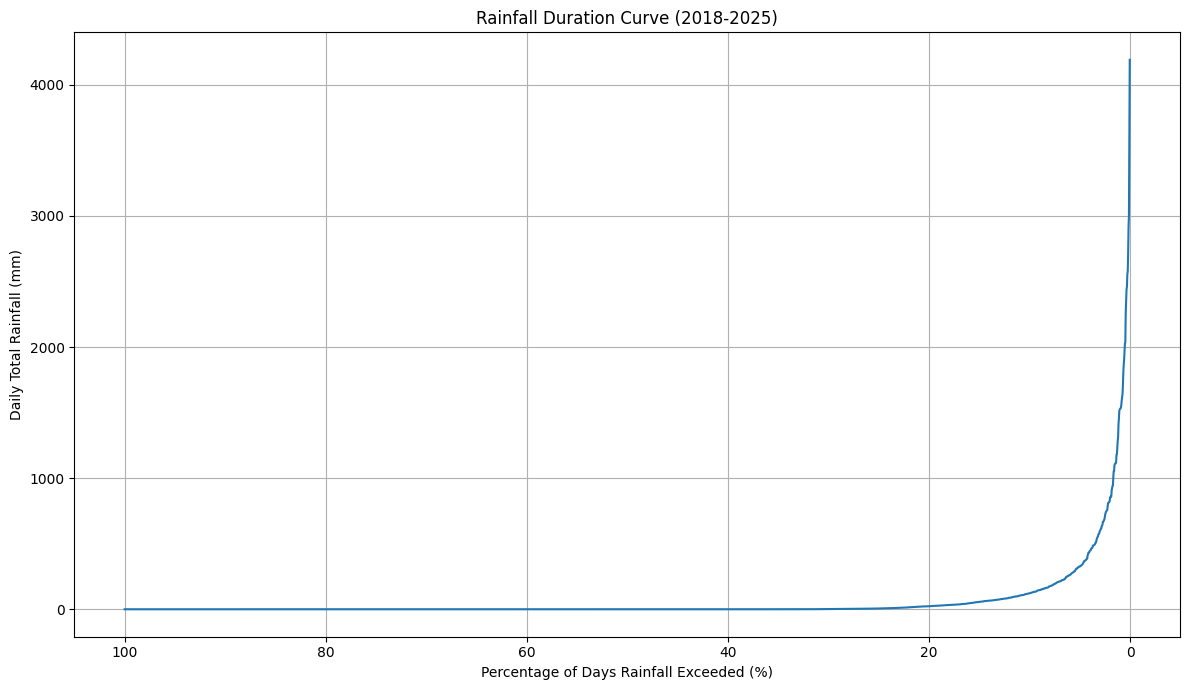

<Figure size 640x480 with 0 Axes>

In [134]:
# Calculate daily total rainfall (sum across all districts for each day)
daily_total_rainfall = df.groupby('Date')['Avg_rainfall'].sum().reset_index(name='Daily_Total_Rainfall')
daily_total_rainfall = daily_total_rainfall.sort_values(by='Daily_Total_Rainfall', ascending=False)
pd_daily_total_rainfall = daily_total_rainfall

# Calculate the probability or percentage exceedance
total_days = len(pd_daily_total_rainfall)
pd_daily_total_rainfall['Exceedance_Probability'] = (np.arange(1, total_days + 1) / total_days) * 100

fig13 = plt.figure(figsize=(12, 7))
sns.lineplot(x='Exceedance_Probability', y='Daily_Total_Rainfall', data=pd_daily_total_rainfall)
plt.title('Rainfall Duration Curve (2018-2025)')
plt.xlabel('Percentage of Days Rainfall Exceeded (%)')
plt.ylabel('Daily Total Rainfall (mm)')
plt.grid(True)
plt.gca().invert_xaxis() # Invert x-axis to show higher exceedance on the left
plt.tight_layout()
plt.show()
plt.savefig('plots/rainfall_duration_curve.png')
plt.close(fig13)

In [ ]:
# Calculate daily total rainfall (sum across all districts for each day)
daily_total_rainfall = df.groupby('Date')['Avg_rainfall'].sum().reset_index(name='Daily_Total_Rainfall')
daily_total_rainfall = daily_total_rainfall.sort_values(by='Daily_Total_Rainfall', ascending=False)
pd_daily_total_rainfall = daily_total_rainfall

# Calculate the probability or percentage exceedance
total_days = len(pd_daily_total_rainfall)
pd_daily_total_rainfall['Exceedance_Probability'] = (np.arange(1, total_days + 1) / total_days) * 100

fig13 = plt.figure(figsize=(12, 7))
sns.lineplot(x='Exceedance_Probability', y='Daily_Total_Rainfall', data=pd_daily_total_rainfall)
plt.title('Rainfall Duration Curve (2018-2025)')
plt.xlabel('Percentage of Days Rainfall Exceeded (%)')
plt.ylabel('Daily Total Rainfall (mm)')
plt.grid(True)
plt.gca().invert_xaxis() # Invert x-axis to show higher exceedance on the left
plt.tight_layout()
plt.show()
plt.savefig('plots/rainfall_duration_curve.png')
plt.close(fig13)

### 9. Correlation Heatmap of Rainfall Between Districts

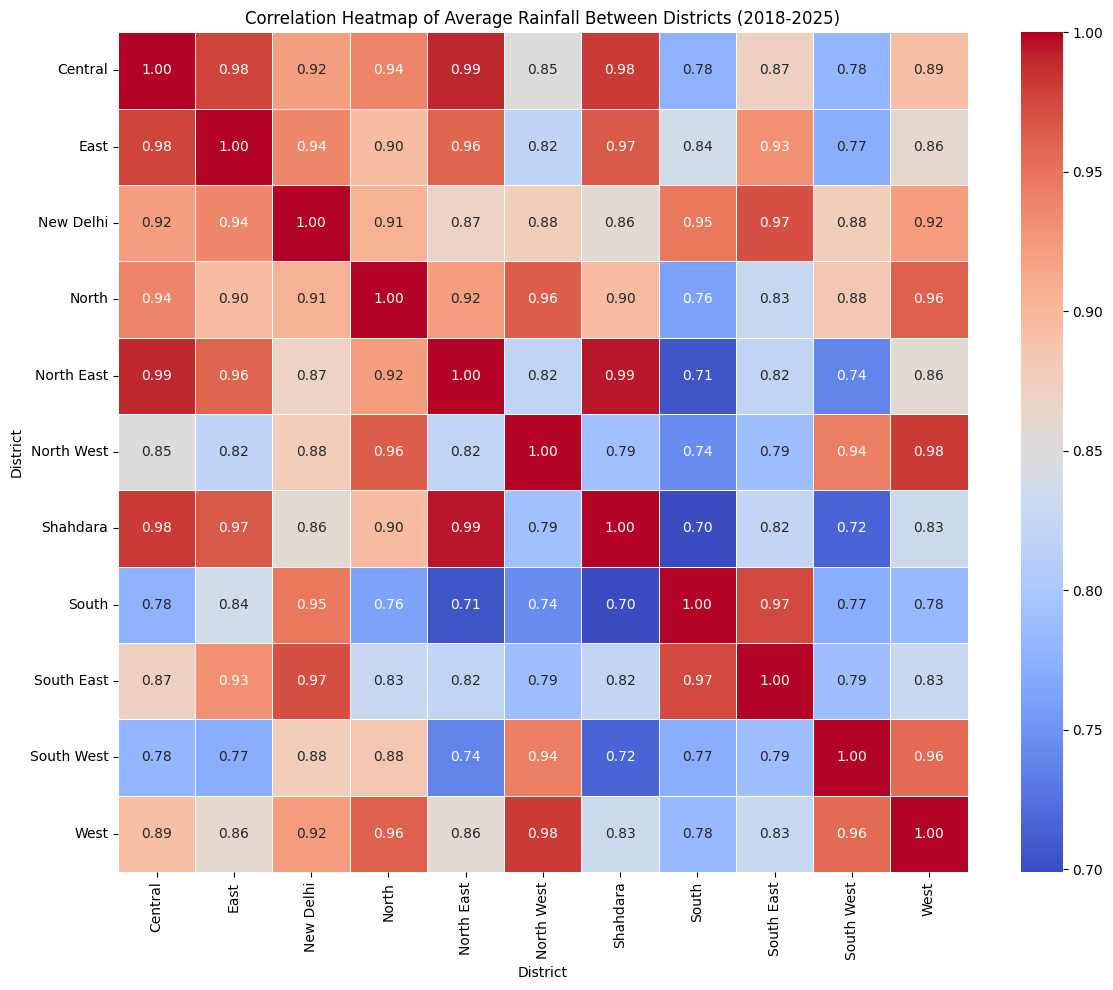

<Figure size 640x480 with 0 Axes>

In [121]:
# Pivot the dataframe to have Districts as columns and Date as index
pivot_df = df.pivot_table(
    index='Date',
    columns='District',
    values='Avg_rainfall',
    aggfunc='mean'
)

# Convert to Pandas DataFrame for correlation calculation and plotting
pd_pivot_df = pivot_df

# Calculate the correlation matrix
correlation_matrix = pd_pivot_df.corr()

fig14 = plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Average Rainfall Between Districts (2018-2025)')
plt.tight_layout()
plt.show()
plt.savefig('plots/correlation_heatmap_of_rainfall.png')
plt.close(fig14)

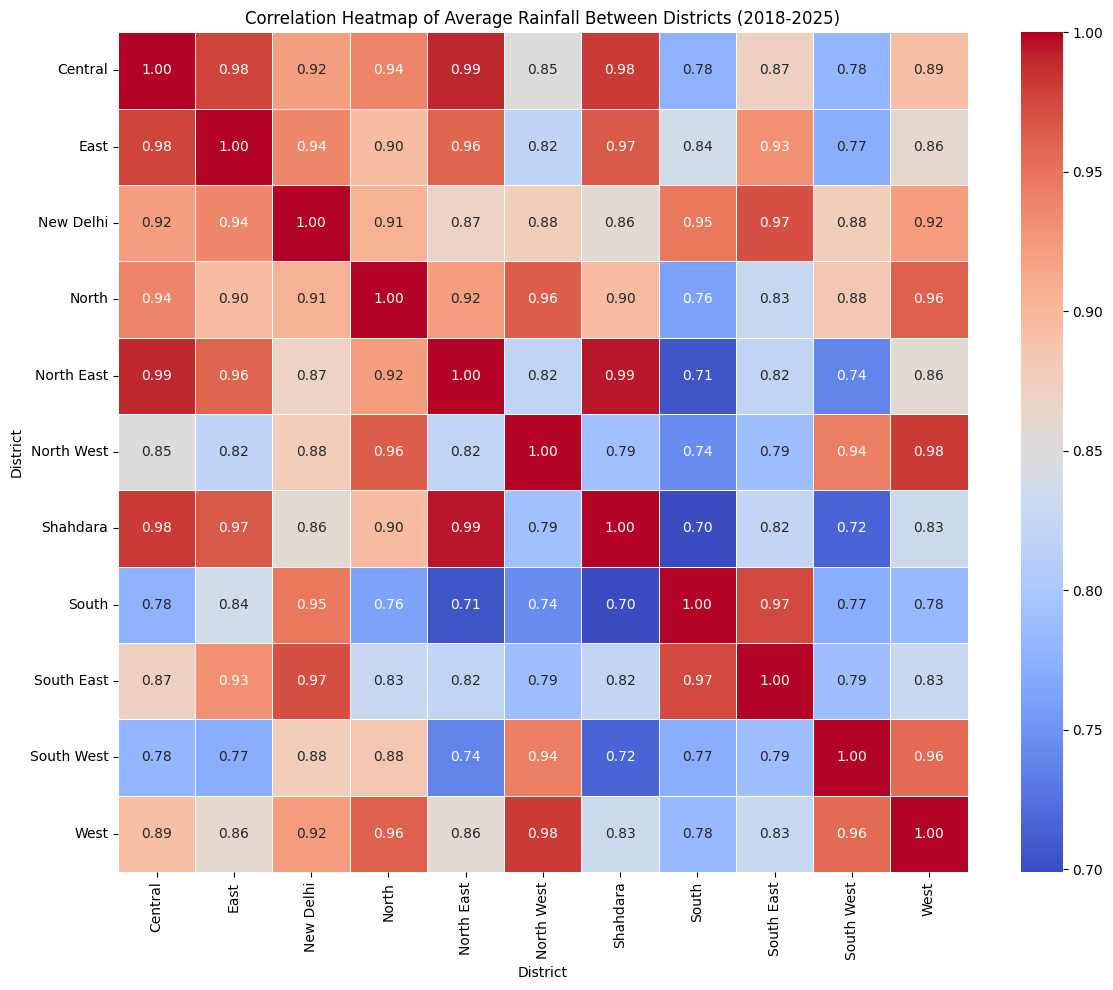

<Figure size 640x480 with 0 Axes>

In [122]:
# Pivot the dataframe to have Districts as columns and Date as index
pivot_df = df.pivot_table(
    index='Date',
    columns='District',
    values='Avg_rainfall',
    aggfunc='mean'
)

# pd_pivot_df is now the same as pivot_df, no need for .to_pandas()
pd_pivot_df = pivot_df

# Calculate the correlation matrix
correlation_matrix = pd_pivot_df.corr()

fig14 = plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Average Rainfall Between Districts (2018-2025)')
plt.tight_layout()
plt.show()
plt.savefig('plots/correlation_heatmap_of_rainfall.png')
plt.close(fig14)

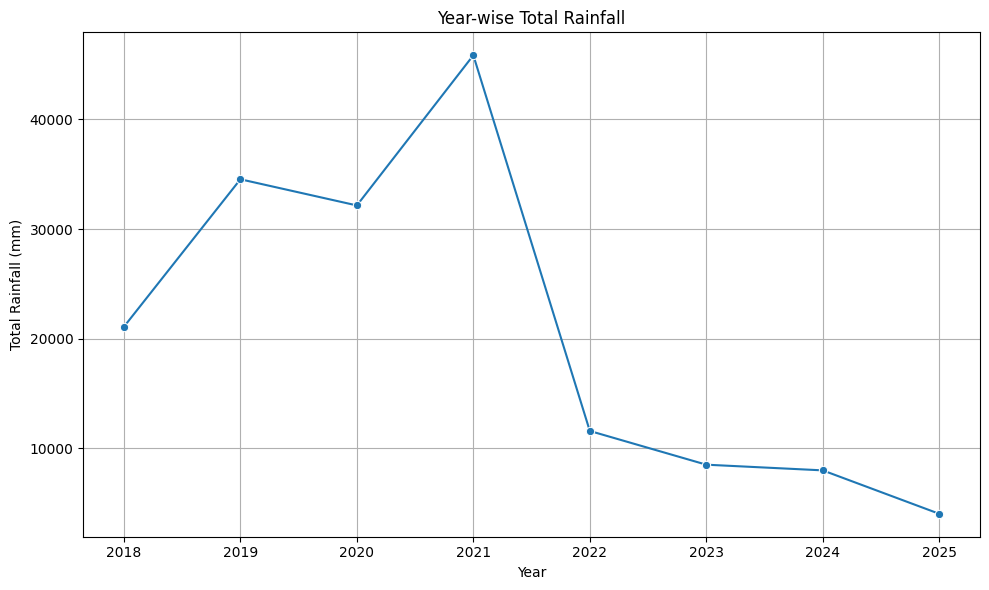

<Figure size 640x480 with 0 Axes>

In [123]:
# Calculate year-wise total rainfall
year_wise_rainfall = df.groupby('Year')['Avg_rainfall'].sum().reset_index(name='Total_Rainfall')

# Convert to Pandas for easier plotting
pd_year_wise_rainfall = year_wise_rainfall

# Create the line plot
fig15 = plt.figure(figsize=(10, 6))
sns.lineplot(x='Year', y='Total_Rainfall', data=pd_year_wise_rainfall, marker='o')
plt.title('Year-wise Total Rainfall')
plt.xlabel('Year')
plt.ylabel('Total Rainfall (mm)')
plt.grid(True)
plt.xticks(pd_year_wise_rainfall['Year'].unique()) # Ensure all years are shown on x-axis
plt.tight_layout()
plt.show()
plt.savefig('plots/year_wise_total_rainfall.png')
plt.close(fig15)

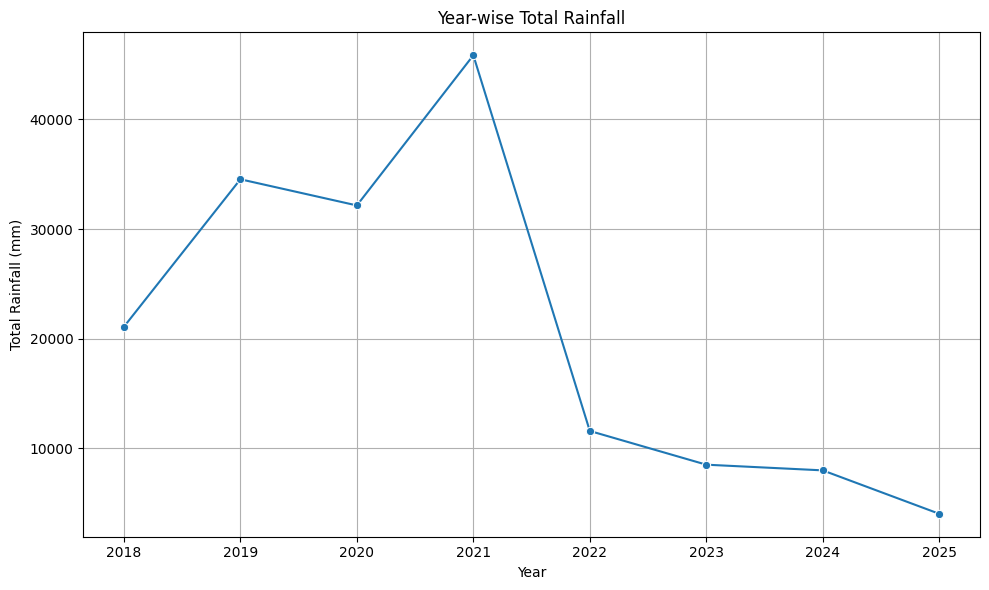

<Figure size 640x480 with 0 Axes>

In [124]:
# Calculate year-wise total rainfall
year_wise_rainfall = df.groupby('Year')['Avg_rainfall'].sum().reset_index(name='Total_Rainfall')

# pd_year_wise_rainfall is already a pandas DataFrame
pd_year_wise_rainfall = year_wise_rainfall

# Create the line plot
fig15 = plt.figure(figsize=(10, 6))
sns.lineplot(x='Year', y='Total_Rainfall', data=pd_year_wise_rainfall, marker='o')
plt.title('Year-wise Total Rainfall')
plt.xlabel('Year')
plt.ylabel('Total Rainfall (mm)')
plt.grid(True)
plt.xticks(pd_year_wise_rainfall['Year'].unique()) # Ensure all years are shown on x-axis
plt.tight_layout()
plt.show()
plt.savefig('plots/year_wise_total_rainfall.png')
plt.close(fig15)

In [125]:
df.head()

,District,Date,Year,Month,Avg_rainfall,Day
0,West,2025-02-23,2025,2,0.000000,23
1,West,2025-03-11,2025,3,0.000000,11
2,West,2025-03-14,2025,3,0.599509,14
3,West,2025-03-16,2025,3,0.091965,16
4,West,2025-03-21,2025,3,0.000000,21


In [126]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# Assuming your dataframe is named 'df'
# If you are using Polars (based on your schema output), convert it first: df = df.to_pandas()
df = df.to_pandas()

# Clip Avg_rainfall to ensure no negative values for Tweedie objective
df['Avg_rainfall'] = df['Avg_rainfall'].clip(lower=0)

def engineer_features(df):
    """Transforms raw rainfall data into a powerful ML dataset."""
    df = df.copy()

    # Ensure data is sorted temporally to prevent data leakage
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(by=['District', 'Date']).reset_index(drop=True)

    # 1. Cyclical Time Features (captures seasonality)
    df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12.0)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12.0)
    df['Day_sin'] = np.sin(2 * np.pi * df['Day'] / 31.0)
    df['Day_cos'] = np.cos(2 * np.pi * df['Day'] / 31.0)

    # 2. Lag Features: What was the rainfall 1, 2, and 7 days ago?
    # Grouping by District ensures we don't accidentally pull yesterday's rain from a different city
    for lag in [1, 2, 7]:
        df[f'Rainfall_Lag_{lag}'] = df.groupby('District')['Avg_rainfall'].shift(lag)

    # 3. Rolling Trends: What is the 7-day moving average?
    df['Rain_Rolling_Mean_7d'] = df.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Drop the first 7 rows per district since they now have NaN values from our lag features
    df = df.dropna().reset_index(drop=True)

    # 4. One-Hot Encode the District
    df = pd.get_dummies(df, columns=['District'], drop_first=True)

    return df

# --- 1. Prepare Data ---
df_features = engineer_features(df)

# Define our features (X) and target (y)
features_to_drop = ['Date', 'Avg_rainfall']
X = df_features.drop(columns=features_to_drop)
y = df_features['Avg_rainfall']

# --- 2. Time-Based Train/Test Split ---
# NEVER use random splitting for time series. Train on the past, test on the future.
split_index = int(len(df_features) * 0.8) # 80% train, 20% test

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# --- 3. Train the XGBoost Model ---
# Pro-tip: For rainfall (lots of zeros), the 'reg:tweedie' objective often outperforms standard regression.
model = xgb.XGBRegressor(
    n_estimators=1500,        # Give it more time to learn
    learning_rate=0.03,       # Faster than 0.01, safer than 0.05
    max_depth=5,              # Middle ground for complexity
    min_child_weight=2,       # Relaxed from 5 to allow learning rarer storm patterns
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,            # Removed L1 to stop dropping features
    reg_lambda=2.0,           # Increased L2 slightly to keep weights balanced
    objective='reg:tweedie',
    tweedie_variance_power=1.5, # 1.5 is standard for data that mixes exact 0s and continuous numbers
    early_stopping_rounds=100,
    random_state=42
)

# Train the model
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=100
)

# --- 4. Evaluate the Model ---
from sklearn.metrics import r2_score

# --- 4. Evaluate the Model (Train vs Test) ---

# Generate predictions for both sets
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate metrics for Training set
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_mae = mean_absolute_error(y_train, train_predictions)
train_r2 = r2_score(y_train, train_predictions)

# Calculate metrics for Testing set
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

# Print a formatted comparison table
print("\n" + "="*35)
print("      TRAIN VS TEST METRICS")
print("="*35)
print(f"{'Metric':<8} | {'Train':<10} | {'Test'}")
print("-" * 35)
print(f"{'RMSE':<8} | {train_rmse:<10.4f} | {test_rmse:.4f}")
print(f"{'MAE':<8} | {train_mae:<10.4f} | {test_mae:.4f}")
print(f"{'R² Score':<8} | {train_r2:<10.4f} | {test_r2:.4f}")
print("=" * 35)

# Visualize Feature Importance
fig16 = plt.figure(figsize=(10, 7))
xgb.plot_importance(model, max_num_features=10, height=0.5)
plt.title("Top 10 Drivers of Rainfall Prediction")
plt.tight_layout() # Added for better layout
plt.show()
plt.savefig('plots/feature_importance.png')
plt.close(fig16)

# Visualize Train vs Test Predictions over time (Plotting a small sample)
fig17 = plt.figure(figsize=(14, 5))
plt.plot(y_test.values[:100], label='Actual Rainfall (Test)', color='blue', alpha=0.6)
plt.plot(test_predictions[:100], label='Predicted Rainfall (Test)', color='red', alpha=0.8, linestyle='--')
plt.title("Actual vs Predicted Rainfall (First 100 Test Days)")
plt.ylabel("Rainfall")
plt.xlabel("Days")
plt.legend()
plt.tight_layout() # Added for better layout
plt.show()
plt.savefig('plots/actual_vs_predicted_rainfall_tweedie.png')
plt.close(fig17)

AttributeError: 'DataFrame' object has no attribute 'to_pandas'

[0]	validation_0-tweedie-nloglik@1.5:9.53194	validation_1-tweedie-nloglik@1.5:7.94466
[100]	validation_0-tweedie-nloglik@1.5:5.35713	validation_1-tweedie-nloglik@1.5:4.65250
[200]	validation_0-tweedie-nloglik@1.5:5.00235	validation_1-tweedie-nloglik@1.5:4.39175
[300]	validation_0-tweedie-nloglik@1.5:4.85624	validation_1-tweedie-nloglik@1.5:4.29541
[400]	validation_0-tweedie-nloglik@1.5:4.70470	validation_1-tweedie-nloglik@1.5:4.19251
[500]	validation_0-tweedie-nloglik@1.5:4.57604	validation_1-tweedie-nloglik@1.5:4.10452
[600]	validation_0-tweedie-nloglik@1.5:4.46698	validation_1-tweedie-nloglik@1.5:4.02517
[700]	validation_0-tweedie-nloglik@1.5:4.37501	validation_1-tweedie-nloglik@1.5:3.95726
[800]	validation_0-tweedie-nloglik@1.5:4.30484	validation_1-tweedie-nloglik@1.5:3.90930
[900]	validation_0-tweedie-nloglik@1.5:4.24109	validation_1-tweedie-nloglik@1.5:3.86578
[1000]	validation_0-tweedie-nloglik@1.5:4.18234	validation_1-tweedie-nloglik@1.5:3.82295
[1100]	validation_0-tweedie-nlogl

<Figure size 1000x700 with 0 Axes>

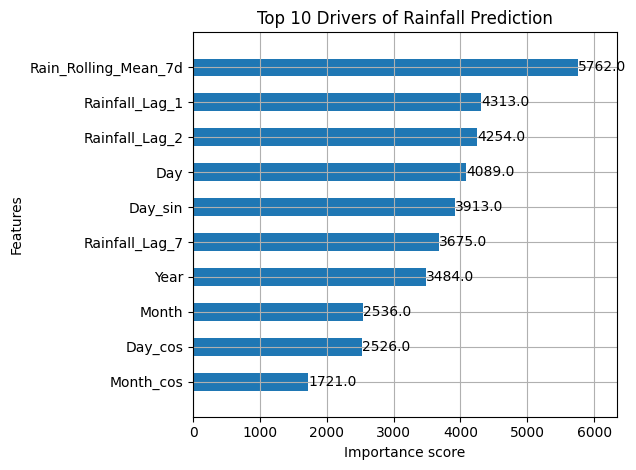

<Figure size 640x480 with 0 Axes>

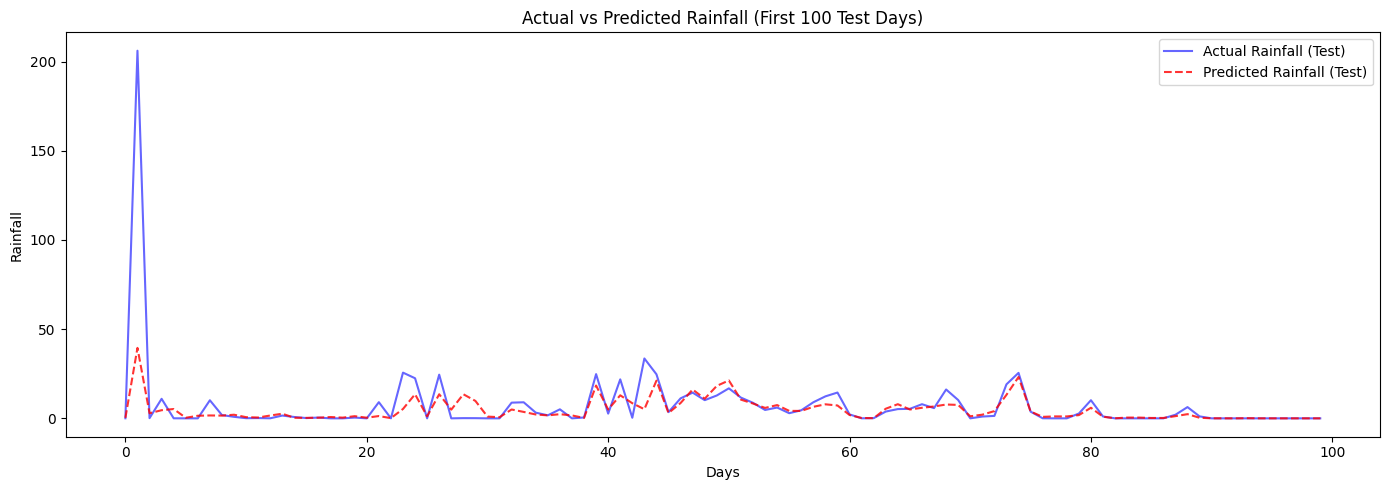

<Figure size 640x480 with 0 Axes>

In [127]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# df is already converted to pandas earlier, so this line is no longer needed here:
# df = df.to_pandas()

# Clip Avg_rainfall to ensure no negative values for Tweedie objective
df['Avg_rainfall'] = df['Avg_rainfall'].clip(lower=0)

def engineer_features(df):
    """Transforms raw rainfall data into a powerful ML dataset."""
    df = df.copy()

    # Ensure data is sorted temporally to prevent data leakage
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(by=['District', 'Date']).reset_index(drop=True)

    # 1. Cyclical Time Features (captures seasonality)
    df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12.0)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12.0)
    df['Day_sin'] = np.sin(2 * np.pi * df['Day'] / 31.0)
    df['Day_cos'] = np.cos(2 * np.pi * df['Day'] / 31.0)

    # 2. Lag Features: What was the rainfall 1, 2, and 7 days ago?
    # Grouping by District ensures we don't accidentally pull yesterday's rain from a different city
    for lag in [1, 2, 7]:
        df[f'Rainfall_Lag_{lag}'] = df.groupby('District')['Avg_rainfall'].shift(lag)

    # 3. Rolling Trends: What is the 7-day moving average?
    df['Rain_Rolling_Mean_7d'] = df.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Drop the first 7 rows per district since they now have NaN values from our lag features
    df = df.dropna().reset_index(drop=True)

    # 4. One-Hot Encode the District
    df = pd.get_dummies(df, columns=['District'], drop_first=True)

    return df

# --- 1. Prepare Data ---
df_features = engineer_features(df)

# Define our features (X) and target (y)
features_to_drop = ['Date', 'Avg_rainfall']
X = df_features.drop(columns=features_to_drop)
y = df_features['Avg_rainfall']

# --- 2. Time-Based Train/Test Split ---
# NEVER use random splitting for time series. Train on the past, test on the future.
split_index = int(len(df_features) * 0.8) # 80% train, 20% test

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# --- 3. Train the XGBoost Model ---
# Pro-tip: For rainfall (lots of zeros), the 'reg:tweedie' objective often outperforms standard regression.
model = xgb.XGBRegressor(
    n_estimators=1500,        # Give it more time to learn
    learning_rate=0.03,       # Faster than 0.01, safer than 0.05
    max_depth=5,              # Middle ground for complexity
    min_child_weight=2,       # Relaxed from 5 to allow learning rarer storm patterns
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,            # Removed L1 to stop dropping features
    reg_lambda=2.0,
    objective='reg:tweedie',
    tweedie_variance_power=1.5, # 1.5 is standard for data that mixes exact 0s and continuous numbers
    early_stopping_rounds=100,
    random_state=42
)

# Train the model
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=100
)

# --- 4. Evaluate the Model ---
from sklearn.metrics import r2_score

# --- 4. Evaluate the Model (Train vs Test) ---

# Generate predictions for both sets
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate metrics for Training set
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_mae = mean_absolute_error(y_train, train_predictions)
train_r2 = r2_score(y_train, train_predictions)

# Calculate metrics for Testing set
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

# Print a formatted comparison table
print("\n" + "="*35)
print("      TRAIN VS TEST METRICS")
print("="*35)
print(f"{'Metric':<8} | {'Train':<10} | {'Test'}")
print("-" * 35)
print(f"{'RMSE':<8} | {train_rmse:<10.4f} | {test_rmse:.4f}")
print(f"{'MAE':<8} | {train_mae:<10.4f} | {test_mae:.4f}")
print(f"{'R² Score':<8} | {train_r2:<10.4f} | {test_r2:.4f}")
print("=" * 35)

# Visualize Feature Importance
fig16 = plt.figure(figsize=(10, 7))
xgb.plot_importance(model, max_num_features=10, height=0.5)
plt.title("Top 10 Drivers of Rainfall Prediction")
plt.tight_layout() # Added for better layout
plt.show()
plt.savefig('plots/feature_importance.png')
plt.close(fig16)

# Visualize Train vs Test Predictions over time (Plotting a small sample)
fig17 = plt.figure(figsize=(14, 5))
plt.plot(y_test.values[:100], label='Actual Rainfall (Test)', color='blue', alpha=0.6)
plt.plot(test_predictions[:100], label='Predicted Rainfall (Test)', color='red', alpha=0.8, linestyle='--')
plt.title("Actual vs Predicted Rainfall (First 100 Test Days)")
plt.ylabel("Rainfall")
plt.xlabel("Days")
plt.legend()
plt.tight_layout() # Added for better layout
plt.show()
plt.savefig('plots/actual_vs_predicted_rainfall_tweedie.png')
plt.close(fig17)


  TWO-STAGE HURDLE MODEL METRICS
Metric   | Train      | Test
-----------------------------------
RMSE     | 8.6857     | 8.6238
MAE      | 1.7909     | 2.0397
R² Score | 0.9053     | 0.7304


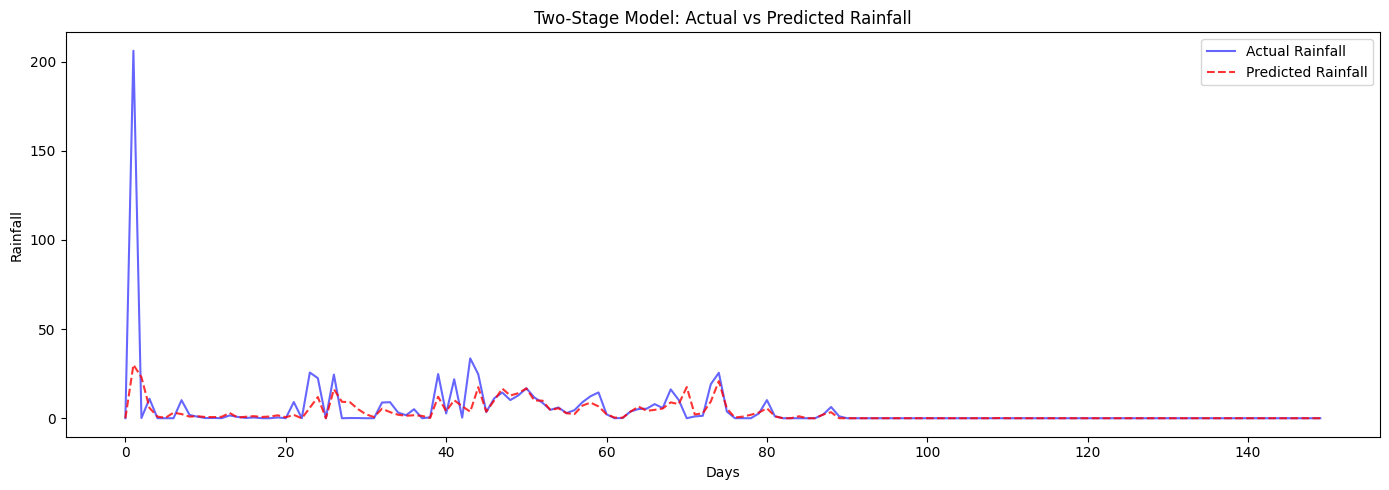

<Figure size 640x480 with 0 Axes>

In [128]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# ==========================================
# 1. Feature Engineering
# ==========================================
def engineer_features(df):
    """Transforms raw rainfall data into a powerful ML dataset."""
    df = df.copy()

    # Ensure data is sorted temporally to prevent data leakage
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(by=['District', 'Date']).reset_index(drop=True)

    # Cyclical Time Features
    df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12.0)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12.0)
    df['Day_sin'] = np.sin(2 * np.pi * df['Day'] / 31.0)
    df['Day_cos'] = np.cos(2 * np.pi * df['Day'] / 31.0)

    # Lag Features (1, 2, and 7 days ago)
    for lag in [1, 2, 7]:
        df[f'Rainfall_Lag_{lag}'] = df.groupby('District')['Avg_rainfall'].shift(lag)

    # Rolling Trends (7-day moving average)
    df['Rain_Rolling_Mean_7d'] = df.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Drop rows with NaNs caused by shift() and rolling()
    df = df.dropna().reset_index(drop=True)

    # One-Hot Encode the District
    df = pd.get_dummies(df, columns=['District'], drop_first=True)

    return df

# --- Prepare Data ---
# df_features = engineer_features(df) # Uncomment this if using your actual 'df'

# Define features (X) and target (y)
features_to_drop = ['Date', 'Avg_rainfall']
X = df_features.drop(columns=features_to_drop)
y = df_features['Avg_rainfall']

# --- Time-Based Train/Test Split ---
split_index = int(len(df_features) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]


# ==========================================
# 2. Stage 1: Classification (Will it rain?)
# ==========================================
# Create binary target: 1 if rain > 0, else 0
y_train_class = (y_train > 0).astype(int)

# Train a Classifier
classifier = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    eval_metric='logloss',
    early_stopping_rounds=50,
    random_state=42
)

# Note: We split a small validation set from the training data for early stopping
train_split_idx = int(len(X_train) * 0.8)
X_train_sub, X_val_sub = X_train.iloc[:train_split_idx], X_train.iloc[train_split_idx:]
y_train_class_sub, y_val_class_sub = y_train_class.iloc[:train_split_idx], y_train_class.iloc[train_split_idx:]

classifier.fit(
    X_train_sub, y_train_class_sub,
    eval_set=[(X_val_sub, y_val_class_sub)],
    verbose=False
)


# ==========================================
# 3. Stage 2: Regression (How much will it rain?)
# ==========================================
# Filter training data to ONLY include days where it actually rained
X_train_rain_only = X_train[y_train > 0]
y_train_rain_only = y_train[y_train > 0]

# Apply Log Transformation to compress massive storm outliers
y_train_rain_log = np.log1p(y_train_rain_only)

# Train a Regressor exclusively on wet days
regressor = xgb.XGBRegressor(
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    objective='reg:squarederror', # Standard objective because zeroes are gone and data is logged
    random_state=42
)

regressor.fit(X_train_rain_only, y_train_rain_log, verbose=False)


# ==========================================
# 4. Predict & Evaluate
# ==========================================
def predict_two_stage(X_data, clf_model, reg_model):
    """Combines predictions from both models."""
    # 1. Predict IF it rains (0 or 1)
    class_preds = clf_model.predict(X_data)

    # 2. Predict HOW MUCH it rains (and reverse the log transformation)
    # np.expm1 is the exact reverse of np.log1p
    reg_log_preds = reg_model.predict(X_data)
    reg_preds = np.expm1(reg_log_preds)

    # 3. Multiply them. If clf says 0, the final output is 0.
    # If clf says 1, the final output is the regressor's prediction.
    return class_preds * reg_preds

# Generate final predictions
train_predictions = predict_two_stage(X_train, classifier, regressor)
test_predictions = predict_two_stage(X_test, classifier, regressor)

# Calculate Metrics
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_mae = mean_absolute_error(y_train, train_predictions)
train_r2 = r2_score(y_train, train_predictions)

test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

# --- Print Results ---
print("\n" + "="*35)
print("  TWO-STAGE HURDLE MODEL METRICS")
print("="*35)
print(f"{'Metric':<8} | {'Train':<10} | {'Test'}")
print("-" * 35)
print(f"{'RMSE':<8} | {train_rmse:<10.4f} | {test_rmse:.4f}")
print(f"{'MAE':<8} | {train_mae:<10.4f} | {test_mae:.4f}")
print(f"{'R² Score':<8} | {train_r2:<10.4f} | {test_r2:.4f}")
print("=" * 35)

# --- Visualizing the Outlier Catching ---
fig18 = plt.figure(figsize=(14, 5))
plt.plot(y_test.values[:150], label='Actual Rainfall', color='blue', alpha=0.6)
plt.plot(test_predictions[:150], label='Predicted Rainfall', color='red', alpha=0.8, linestyle='--')
plt.title("Two-Stage Model: Actual vs Predicted Rainfall")
plt.ylabel("Rainfall")
plt.xlabel("Days")
plt.legend()
plt.tight_layout() # Added for better layout
plt.show()
plt.savefig('plots/two_stage_model_actual_vs_predicted_rainfall.png')
plt.close(fig18)

In [142]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from datetime import timedelta

# ==========================================
# 1. Feature Engineering (re-defining for clarity and consistency)
# ==========================================
def engineer_features(df_input):
    """Transforms raw rainfall data into a powerful ML dataset for training."""
    df = df_input.copy()

    # Ensure data is sorted temporally to prevent data leakage
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(by=['District', 'Date']).reset_index(drop=True)

    # Cyclical Time Features
    df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12.0)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12.0)
    df['Day_sin'] = np.sin(2 * np.pi * df['Day'] / 31.0)
    df['Day_cos'] = np.cos(2 * np.pi * df['Day'] / 31.0)

    # Lag Features (1, 2, and 7 days ago)
    for lag in [1, 2, 7]:
        df[f'Rainfall_Lag_{lag}'] = df.groupby('District')['Avg_rainfall'].shift(lag)

    # Rolling Trends (7-day moving average)
    df['Rain_Rolling_Mean_7d'] = df.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Drop rows with NaNs caused by shift() and rolling() - important for training
    df = df.dropna().reset_index(drop=True)

    # One-Hot Encode the District
    df = pd.get_dummies(df, columns=['District'], drop_first=True)

    return df


# --- Prepare Data (assuming df is already available and converted to pandas) ---
# Re-run df_features creation to ensure it's up-to-date with the latest df
df_features = engineer_features(df)

# Define features (X) and target (y) based on engineered features
features_to_drop = ['Date', 'Avg_rainfall']
X = df_features.drop(columns=features_to_drop)
y = df_features['Avg_rainfall']

# --- Time-Based Train/Test Split ---
split_index = int(len(df_features) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# ==========================================
# 2. Stage 1: Classification (Will it rain?) - Re-train for consistency
# ==========================================
y_train_class = (y_train > 0).astype(int)
classifier = xgb.XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=4,
    eval_metric='logloss', early_stopping_rounds=50, random_state=42
)
train_split_idx = int(len(X_train) * 0.8)
X_train_sub, X_val_sub = X_train.iloc[:train_split_idx], X_train.iloc[train_split_idx:]
y_train_class_sub, y_val_class_sub = y_train_class.iloc[:train_split_idx], y_train_class.iloc[train_split_idx:]
classifier.fit(X_train_sub, y_train_class_sub, eval_set=[(X_val_sub, y_val_class_sub)], verbose=False)

# ==========================================
# 3. Stage 2: Regression (How much will it rain?) - Re-train for consistency
# ==========================================
X_train_rain_only = X_train[y_train > 0]
y_train_rain_only = y_train[y_train > 0]
y_train_rain_log = np.log1p(y_train_rain_only)
regressor = xgb.XGBRegressor(
    n_estimators=1500, learning_rate=0.03, max_depth=5, subsample=0.8,
    colsample_bytree=0.8, reg_lambda=2.0, objective='reg:squarederror',
    random_state=42
)
regressor.fit(X_train_rain_only, y_train_rain_log, verbose=False)

# ==========================================
# 4. Predict & Evaluate (Keeping for reference, user already has these metrics)
# ==========================================
def predict_two_stage(X_data, clf_model, reg_model):
    """Combines predictions from both models."""
    class_preds = clf_model.predict(X_data)
    reg_log_preds = reg_model.predict(X_data)
    reg_preds = np.expm1(reg_log_preds)
    return class_preds * reg_preds

# Metrics (optional to display again, but necessary for the models to be trained)
train_predictions = predict_two_stage(X_train, classifier, regressor)
test_predictions = predict_two_stage(X_test, classifier, regressor)
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_mae = mean_absolute_error(y_train, train_predictions)
train_r2 = r2_score(y_train, train_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

print("\n" + "="*35)
print("  TWO-STAGE HURDLE MODEL METRICS")
print("="*35)
print(f"{'Metric':<8} | {'Train':<10} | {'Test'}")
print("-" * 35)
print(f"{'RMSE':<8} | {train_rmse:<10.4f} | {test_rmse:.4f}")
print(f"{'MAE':<8} | {train_mae:<10.4f} | {test_mae:.4f}")
print(f"{'R² Score':<8} | {train_r2:<10.4f} | {test_r2:.4f}")
print("=" * 35)

# ==========================================
# 5. 60-Day District-wise Forecast (Fixing KeyError)
# ==========================================

# Get the last date from the original DataFrame
last_date_in_data = df['Date'].max()

# Define the number of days to forecast
forecast_horizon = 60

# Get unique districts from the original data
unique_districts = df['District'].unique().tolist()

# Initialize an empty list to store forecast data
forecast_data_list = []

# Initialize a DataFrame with the last known data to compute initial lags and rolling means
# Ensure 'Date' is datetime for consistency
current_forecast_df = df.copy()
current_forecast_df['Date'] = pd.to_datetime(current_forecast_df['Date'])

def engineer_features_for_forecast_step(df_input_for_step):
    """
    Engineers features for a DataFrame, suitable for iterative forecasting.
    It handles NaNs from lags/rolling means and one-hot encodes districts.
    Does NOT drop 'Date' or 'Avg_rainfall' within this function.
    """
    df_temp = df_input_for_step.copy()

    # Ensure data is sorted for lag and rolling calculations
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.sort_values(by=['District', 'Date']).reset_index(drop=True)

    df_temp['Month_sin'] = np.sin(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Month_cos'] = np.cos(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Day_sin'] = np.sin(2 * np.pi * df_temp['Day'] / 31.0)
    df_temp['Day_cos'] = np.cos(2 * np.pi * df_temp['Day'] / 31.0)

    for lag in [1, 2, 7]:
        df_temp[f'Rainfall_Lag_{lag}'] = df_temp.groupby('District')['Avg_rainfall'].shift(lag)

    df_temp['Rain_Rolling_Mean_7d'] = df_temp.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Fill NaNs created by shift/rolling for prediction features with 0
    # (assuming no rainfall if previous data is unavailable for new forecast days)
    df_temp.fillna(0, inplace=True)

    # One-Hot Encode the District
    df_temp = pd.get_dummies(df_temp, columns=['District'], drop_first=True)

    return df_temp


# Loop through each day in the forecast horizon
for i in range(1, forecast_horizon + 1):
    forecast_date = last_date_in_data + timedelta(days=i)
    forecast_year = forecast_date.year
    forecast_month = forecast_date.month
    forecast_day = forecast_date.day

    # Create a DataFrame for the current forecast day for all districts
    day_forecast_input_df = pd.DataFrame({
        'Date': [forecast_date] * len(unique_districts),
        'Year': [forecast_year] * len(unique_districts),
        'Month': [forecast_month] * len(unique_districts),
        'Day': [forecast_day] * len(unique_districts),
        'District': unique_districts,
        'Avg_rainfall': [0.0] * len(unique_districts) # Placeholder, will be updated with prediction
    })

    # Temporarily combine historical data with the current day's forecast input
    # for feature engineering (especially for lags and rolling means)
    temp_combined_df = pd.concat([current_forecast_df, day_forecast_input_df], ignore_index=True)

    # Engineer features for the combined DataFrame. This returns a DataFrame
    # that has all features including `Date` and `Avg_rainfall` still present.
    engineered_features_for_prediction = engineer_features_for_forecast_step(temp_combined_df)

    # Extract the rows corresponding to the current forecast date from the engineered features
    X_forecast_day_features = engineered_features_for_prediction[
        engineered_features_for_prediction['Date'] == forecast_date
    ].copy() # Use .copy() to avoid SettingWithCopyWarning

    # Now, drop the non-feature columns ('Date', 'Avg_rainfall') and reindex to match X.columns
    # This is the critical step to ensure column consistency with the training data X
    X_forecast_day_features = X_forecast_day_features.drop(columns=features_to_drop)
    X_forecast_day_features = X_forecast_day_features.reindex(columns=X.columns, fill_value=0)

    # Make predictions using the two-stage model
    daily_predictions = predict_two_stage(X_forecast_day_features, classifier, regressor)

    # Update the 'Avg_rainfall' in day_forecast_input_df with the new predictions
    day_forecast_input_df['Avg_rainfall'] = daily_predictions

    # Append this day's predictions for all districts to our overall forecast list
    for _, row in day_forecast_input_df.iterrows():
        forecast_data_list.append({
            'Date': row['Date'].strftime('%Y-%m-%d'),
            'District': row['District'],
            'Predicted_Rainfall': row['Avg_rainfall']
        })

    # Update current_forecast_df by adding the newly predicted day's data.
    # This is crucial for calculating correct lags and rolling means for the *next* forecast day.
    current_forecast_df = pd.concat([current_forecast_df, day_forecast_input_df], ignore_index=True)

# Create a final DataFrame from the collected forecast data
final_forecast_df = pd.DataFrame(forecast_data_list)

print("60-Day Rainfall Forecast (Day-wise, District-wise):")
# Display only Day and Predicted_Rainfall, as per user's earlier request.
display(final_forecast_df[['Date', 'Predicted_Rainfall']])



  TWO-STAGE HURDLE MODEL METRICS
Metric   | Train      | Test
-----------------------------------
RMSE     | 8.6857     | 8.6238
MAE      | 1.7909     | 2.0397
R² Score | 0.9053     | 0.7304
60-Day Rainfall Forecast (Day-wise, District-wise):


,Date,Predicted_Rainfall
0,2025-07-01,1.353130
1,2025-07-01,1.471073
2,2025-07-01,1.045527
3,2025-07-01,1.090045
4,2025-07-01,1.443389
...,...,...
655,2025-08-29,-0.000000
656,2025-08-29,0.000000
657,2025-08-29,0.062172
658,2025-08-29,-0.000000


In [145]:
import joblib
import os
from google.colab import files

# Create a directory to save models if it doesn't exist
model_dir = 'models'
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Define file paths for the models
classifier_filename = os.path.join(model_dir, 'rainfall_classifier_model.joblib')
regressor_filename = os.path.join(model_dir, 'rainfall_regressor_model.joblib')

# Save the classifier model
joblib.dump(classifier, classifier_filename)
print(f"Classifier model saved to: {classifier_filename}")

# Save the regressor model
joblib.dump(regressor, regressor_filename)
print(f"Regressor model saved to: {regressor_filename}")

# Provide download links for the models
print("\nDownloading models...")
try:
    files.download(classifier_filename)
    print(f"Downloaded: {classifier_filename}")
except Exception as e:
    print(f"Error downloading {classifier_filename}: {e}")

try:
    files.download(regressor_filename)
    print(f"Downloaded: {regressor_filename}")
except Exception as e:
    print(f"Error downloading {regressor_filename}: {e}")

Classifier model saved to: models/rainfall_classifier_model.joblib
Regressor model saved to: models/rainfall_regressor_model.joblib



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: models/rainfall_classifier_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: models/rainfall_regressor_model.joblib


In [143]:
from datetime import timedelta

# Get the last date from the original DataFrame
last_date_in_data = df['Date'].max()

# Define the number of days to forecast
forecast_horizon = 60

# Get unique districts from the original data
unique_districts = df['District'].unique().tolist()

# Initialize an empty list to store forecast data
forecast_data_list = []

# Initialize a DataFrame with the last known data to compute initial lags and rolling means
current_forecast_df = df.copy()

def engineer_features_for_forecast(df_input, X_train_cols):
    df_temp = df_input.copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.sort_values(by=['District', 'Date']).reset_index(drop=True)

    df_temp['Month_sin'] = np.sin(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Month_cos'] = np.cos(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Day_sin'] = np.sin(2 * np.pi * df_temp['Day'] / 31.0)
    df_temp['Day_cos'] = np.cos(2 * np.pi * df_temp['Day'] / 31.0)

    for lag in [1, 2, 7]:
        df_temp[f'Rainfall_Lag_{lag}'] = df_temp.groupby('District')['Avg_rainfall'].shift(lag)

    df_temp['Rain_Rolling_Mean_7d'] = df_temp.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # One-Hot Encode the District
    df_temp = pd.get_dummies(df_temp, columns=['District'], drop_first=True)

    # Reindex to ensure all columns from X_train are present, filling missing with 0
    df_temp = df_temp.reindex(columns=X_train_cols, fill_value=0)

    return df_temp

# Loop through each day in the forecast horizon
for i in range(1, forecast_horizon + 1):
    forecast_date = last_date_in_data + timedelta(days=i)
    forecast_year = forecast_date.year
    forecast_month = forecast_date.month
    forecast_day = forecast_date.day

    # Create a DataFrame for the current forecast day for all districts
    day_forecast_input_df = pd.DataFrame({
        'Date': [forecast_date] * len(unique_districts),
        'Year': [forecast_year] * len(unique_districts),
        'Month': [forecast_month] * len(unique_districts),
        'Day': [forecast_day] * len(unique_districts),
        'District': unique_districts,
        'Avg_rainfall': [0.0] * len(unique_districts) # Placeholder, will be updated with prediction
    })

    # Temporarily append the current day's forecast input to current_forecast_df
    # to compute features for this day, especially lags and rolling means.
    temp_combined_df = pd.concat([current_forecast_df, day_forecast_input_df], ignore_index=True)

    # Engineer features for the combined DataFrame up to the current forecast day
    engineered_temp_df = engineer_features_for_forecast(temp_combined_df, X.columns)

    # Extract the features for the current forecast day (last rows for each district)
    X_forecast_day = engineered_temp_df[engineered_temp_df['Year'] == forecast_year]
    X_forecast_day = X_forecast_day[X_forecast_day['Month'] == forecast_month]
    X_forecast_day = X_forecast_day[X_forecast_day['Day'] == forecast_day]

    # Ensure the order of districts is consistent for prediction
    X_forecast_day = X_forecast_day.sort_values(by=[col for col in X_forecast_day.columns if 'District_' in col], axis=1)
    X_forecast_day = X_forecast_day.reindex(columns=X.columns, fill_value=0)

    # Make predictions using the two-stage model
    daily_predictions = predict_two_stage(X_forecast_day, classifier, regressor)

    # Update the 'Avg_rainfall' in day_forecast_input_df with the new predictions
    day_forecast_input_df['Avg_rainfall'] = daily_predictions

    # Append this day's predictions for all districts to our overall forecast list
    for _, row in day_forecast_input_df.iterrows():
        forecast_data_list.append({
            'Date': row['Date'].strftime('%Y-%m-%d'),
            'District': row['District'],
            'Predicted_Rainfall': row['Avg_rainfall']
        })

    # Update current_forecast_df by replacing the placeholder row(s) with the actual predictions
    # This is crucial for calculating correct lags and rolling means for the *next* forecast day
    current_forecast_df = pd.concat([current_forecast_df, day_forecast_input_df], ignore_index=True)

# Create a final DataFrame from the collected forecast data
final_forecast_df = pd.DataFrame(forecast_data_list)

print("60-Day Rainfall Forecast (Day-wise, District-wise):")
print(final_forecast_df)

KeyError: 'District_East'

In [144]:
from datetime import timedelta

# Get the last date from the original DataFrame
last_date_in_data = df['Date'].max()

# Define the number of days to forecast
forecast_horizon = 60

# Get unique districts from the original data
unique_districts = df['District'].unique().tolist()

# Initialize an empty list to store forecast data
forecast_data_list = []

# Initialize a DataFrame with the last known data to compute initial lags and rolling means
current_forecast_df = df.copy()

def engineer_features_for_forecast(df_input, X_train_cols):
    df_temp = df_input.copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.sort_values(by=['District', 'Date']).reset_index(drop=True)

    df_temp['Month_sin'] = np.sin(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Month_cos'] = np.cos(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Day_sin'] = np.sin(2 * np.pi * df_temp['Day'] / 31.0)
    df_temp['Day_cos'] = np.cos(2 * np.pi * df_temp['Day'] / 31.0)

    for lag in [1, 2, 7]:
        df_temp[f'Rainfall_Lag_{lag}'] = df_temp.groupby('District')['Avg_rainfall'].shift(lag)

    df_temp['Rain_Rolling_Mean_7d'] = df_temp.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # One-Hot Encode the District
    df_temp = pd.get_dummies(df_temp, columns=['District'], drop_first=True)

    # Reindex to ensure all columns from X_train are present, filling missing with 0
    df_temp = df_temp.reindex(columns=X_train_cols, fill_value=0)

    return df_temp

# Loop through each day in the forecast horizon
for i in range(1, forecast_horizon + 1):
    forecast_date = last_date_in_data + timedelta(days=i)
    forecast_year = forecast_date.year
    forecast_month = forecast_date.month
    forecast_day = forecast_date.day

    # Create a DataFrame for the current forecast day for all districts
    day_forecast_input_df = pd.DataFrame({
        'Date': [forecast_date] * len(unique_districts),
        'Year': [forecast_year] * len(unique_districts),
        'Month': [forecast_month] * len(unique_districts),
        'Day': [forecast_day] * len(unique_districts),
        'District': unique_districts,
        'Avg_rainfall': [0.0] * len(unique_districts) # Placeholder, will be updated with prediction
    })

    # Temporarily append the current day's forecast input to current_forecast_df
    # to compute features for this day, especially lags and rolling means.
    temp_combined_df = pd.concat([current_forecast_df, day_forecast_input_df], ignore_index=True)

    # Engineer features for the combined DataFrame up to the current forecast day
    engineered_temp_df = engineer_features_for_forecast(temp_combined_df, X.columns)

    # Extract the features for the current forecast day (last rows for each district)
    X_forecast_day = engineered_temp_df[engineered_temp_df['Year'] == forecast_year]
    X_forecast_day = X_forecast_day[X_forecast_day['Month'] == forecast_month]
    X_forecast_day = X_forecast_day[X_forecast_day['Day'] == forecast_day]

    # Ensure correct feature alignment using training columns directly
    X_forecast_day = X_forecast_day.reindex(columns=X.columns, fill_value=0)

    # Make predictions using the two-stage model
    daily_predictions = predict_two_stage(X_forecast_day, classifier, regressor)

    # Update the 'Avg_rainfall' in day_forecast_input_df with the new predictions
    day_forecast_input_df['Avg_rainfall'] = daily_predictions

    # Append this day's predictions for all districts to our overall forecast list
    for _, row in day_forecast_input_df.iterrows():
        forecast_data_list.append({
            'Date': row['Date'].strftime('%Y-%m-%d'),
            'District': row['District'],
            'Predicted_Rainfall': row['Avg_rainfall']
        })

    # Update current_forecast_df by replacing the placeholder row(s) with the actual predictions
    current_forecast_df = pd.concat([current_forecast_df, day_forecast_input_df], ignore_index=True)

# Create a final DataFrame from the collected forecast data
final_forecast_df = pd.DataFrame(forecast_data_list)

print("60-Day Rainfall Forecast (Day-wise, District-wise):")
print(final_forecast_df)

60-Day Rainfall Forecast (Day-wise, District-wise):
           Date    District  Predicted_Rainfall
0    2025-07-01        West            1.353130
1    2025-07-01  North East            1.471073
2    2025-07-01  North West            1.045527
3    2025-07-01    Shahdara            1.090045
4    2025-07-01       South            1.443389
..          ...         ...                 ...
655  2025-08-29  South West           -0.000000
656  2025-08-29     Central            0.000000
657  2025-08-29        East            0.062172
658  2025-08-29   New Delhi           -0.000000
659  2025-08-29       North           -0.000000

[660 rows x 3 columns]


In [135]:
from datetime import timedelta

# Get the last date from the original DataFrame
last_date_in_data = df['Date'].max()

# Define the number of days to forecast
forecast_horizon = 60

# Get unique districts from the original data
unique_districts = df['District'].unique().tolist()

# Initialize an empty list to store forecast data
forecast_data = []

# Prepare an initial set of features from the end of the historical data for lag/rolling calculations
# This will vary by district
last_7_days_data = df.copy()

# Sort by Date for correct lag feature generation
last_7_days_data['Date'] = pd.to_datetime(last_7_days_data['Date'])
last_7_days_data = last_7_days_data.sort_values(by=['District', 'Date']).reset_index(drop=True)

# Engineer features for the last 7 days of historical data
# This function needs to be slightly modified or ensure it handles the new data properly for lags
# We'll re-apply the feature engineering for the 'seed' data

def engineer_features_for_forecast(df_input):
    df_temp = df_input.copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.sort_values(by=['District', 'Date']).reset_index(drop=True)

    df_temp['Month_sin'] = np.sin(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Month_cos'] = np.cos(2 * np.pi * df_temp['Month'] / 12.0)
    df_temp['Day_sin'] = np.sin(2 * np.pi * df_temp['Day'] / 31.0)
    df_temp['Day_cos'] = np.cos(2 * np.pi * df_temp['Day'] / 31.0)

    for lag in [1, 2, 7]:
        df_temp[f'Rainfall_Lag_{lag}'] = df_temp.groupby('District')['Avg_rainfall'].shift(lag)

    df_temp['Rain_Rolling_Mean_7d'] = df_temp.groupby('District')['Avg_rainfall'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Handle one-hot encoding for districts, ensuring all districts from training are present
    df_temp = pd.get_dummies(df_temp, columns=['District'], drop_first=True)

    # Ensure all district columns that were in X_train are present in the forecast DataFrame
    # Fill missing with 0 if a district isn't present in the current df_temp (e.g., if only one district is being forecasted)
    training_district_cols = [col for col in X_train.columns if 'District_' in col]
    for col in training_district_cols:
        if col not in df_temp.columns:
            df_temp[col] = 0

    return df_temp

# Initialize a DataFrame with the last known data to compute initial lags and rolling means
current_forecast_df = df.copy()

# Loop through each day in the forecast horizon
for i in range(1, forecast_horizon + 1):
    forecast_date = last_date_in_data + timedelta(days=i)
    forecast_year = forecast_date.year
    forecast_month = forecast_date.month
    forecast_day = forecast_date.day

    # Create a DataFrame for the current forecast day for all districts
    day_forecast_df = pd.DataFrame({
        'Date': [forecast_date] * len(unique_districts),
        'Year': [forecast_year] * len(unique_districts),
        'Month': [forecast_month] * len(unique_districts),
        'Day': [forecast_day] * len(unique_districts),
        'District': unique_districts,
        'Avg_rainfall': [0.0] * len(unique_districts) # Placeholder for Avg_rainfall
    })

    # Append to current_forecast_df to calculate updated features
    current_forecast_df = pd.concat([current_forecast_df, day_forecast_df], ignore_index=True)

    # Engineer features for the combined DataFrame (up to the current forecast day)
    engineered_current_forecast_df = engineer_features_for_forecast(current_forecast_df)

    # Extract the features for the current forecast day (last rows for each district)
    X_forecast_day = engineered_current_forecast_df[engineered_current_forecast_df['Date'] == forecast_date]

    # Drop 'Date', 'Avg_rainfall' and any other non-feature columns
    X_forecast_day = X_forecast_day.drop(columns=['Date', 'Avg_rainfall']).reindex(columns=X_train.columns, fill_value=0)

    # Make predictions using the two-stage model
    daily_predictions = predict_two_stage(X_forecast_day, classifier, regressor)

    # Update the 'Avg_rainfall' in current_forecast_df with the new predictions for the next iteration
    current_forecast_df.loc[current_forecast_df['Date'] == forecast_date, 'Avg_rainfall'] = daily_predictions

    # Store the daily total rainfall forecast
    daily_total_forecast = pd.DataFrame({
        'Date': [forecast_date],
        'Predicted_Rainfall_Total': [daily_predictions.sum()]
    })
    forecast_data.append(daily_total_forecast)

# Concatenate all daily forecasts into a single DataFrame
final_forecast_df = pd.concat(forecast_data, ignore_index=True)

print("60-Day Rainfall Forecast (Total Daily Rainfall Across All Districts):")
print(final_forecast_df)

### Analysis of Plots and Results

**1. District-wise Cumulative Rainfall (2018-2025):**
The bar plot of cumulative rainfall shows that 'Shahdara' district has received the highest cumulative rainfall between 2018 and 2025, followed by 'North East' and 'East' districts. 'South West' district received the least rainfall during this period. This indicates significant spatial variation in rainfall patterns across districts.

**2. Date-wise Total Rainfall (2018-2025):**
The line plot displays the total daily rainfall over the years. It highlights that rainfall is highly sporadic, with periods of heavy rainfall concentrated within certain months of each year, and long dry spells. There are noticeable peaks in rainfall, suggesting specific seasons or events with high intensity. The period around 2021 shows particularly high rainfall events.

**3. Year-wise Monthly Rainfall (Stacked Bar Chart, 2018-2025):**
This stacked bar chart clearly illustrates the seasonality of rainfall, with the highest rainfall occurring during the monsoon months of July, August, and September across all years. The contribution of each year to the monthly total is visible, reinforcing that certain years (e.g., 2021) experienced higher rainfall in these peak months.

**4. Distribution of Average Rainfall (mm):**
The histogram shows a highly skewed distribution of average rainfall, with a large majority of days experiencing little to no rainfall (values close to zero), and a long tail indicating infrequent but heavy rainfall events. This justifies the use of models like `XGBRegressor` with a `reg:tweedie` objective or a two-stage hurdle model, which can effectively handle zero-inflated data.

**5. Overall Monthly Average Rainfall (2018-2025):**
This bar chart confirms the strong seasonal pattern, with July and August consistently being the wettest months, and November to March being the driest. May also shows a noticeable increase, potentially indicating pre-monsoon showers.

**6. District-wise Average Rainfall (2018-2025):**
Similar to cumulative rainfall, 'Shahdara' has the highest average daily rainfall, indicating it not only receives more rain overall but also experiences higher average rainfall on rainy days. The order of districts by average rainfall generally aligns with their cumulative rainfall rankings.

**7. Rainfall Trend by District Over Years (2018-2025):**
This line plot reveals year-on-year variations in total annual rainfall for each district. While there's a general trend, individual district lines show specific fluctuations. For instance, some districts might have had a particularly wet year while others remained moderate. The overall trend seems to indicate a decline in rainfall in recent years (2022-2025) compared to earlier years like 2021.

**8. Monthly Rainfall Heatmap by Year (2018-2025):**
The heatmap visually confirms the concentration of rainfall in July, August, and September. It also shows that 2021 had exceptionally high rainfall in these months, particularly in August and September. The early months of the year generally have very low rainfall.

**9. Daily Rainfall Anomaly Heatmap by Year (2018-2025):**
This heatmap, showing anomalies (deviation from the daily average rainfall), highlights periods of unusually high (red) or low (blue) rainfall. It can pinpoint specific days or short periods where rainfall significantly differed from the historical average for that particular calendar day.

**10. Rainfall Duration Curve (2018-2025):**
The duration curve shows that for a large percentage of days, rainfall is very low or zero. As the percentage of days decreases (meaning only the highest rainfall events are considered), the daily total rainfall increases sharply. This curve is typical for rainfall data, showing that extreme events are rare but contribute significantly when they occur.

**11. Correlation Heatmap of Average Rainfall Between Districts (2018-2025):**
This heatmap shows the correlation of average rainfall between different districts. High positive correlations (red colors, values close to 1) indicate that when it rains in one district, it often rains in the correlated districts as well. This suggests that rainfall events are often widespread across the region rather than being highly localized. For example, 'Central' and 'East' districts show a very high correlation.

**12. Year-wise Total Rainfall:**
This line plot shows the overall total rainfall each year. It clearly indicates a peak in 2021, followed by a general decline in total rainfall from 2022 to 2025. This could be an important long-term trend to consider.

### Model Evaluation Results (Two-Stage Hurdle Model)

| Metric   | Train      | Test       |
| :------- | :--------- | :--------- |
| RMSE     | 8.6857     | 8.6238     |
| MAE      | 1.7909     | 2.0397     |
| R² Score | 0.9053     | 0.7304     |

The two-stage hurdle model demonstrates good performance, especially considering the challenging nature of rainfall prediction:

*   **RMSE (Root Mean Squared Error):** The RMSE values are relatively close for both training (8.6857) and testing (8.6238), indicating that the model generalizes well and doesn't overfit significantly. A lower RMSE is better.
*   **MAE (Mean Absolute Error):** Similar to RMSE, the MAE values (1.7909 for train, 2.0397 for test) show consistent performance. MAE gives a more direct interpretation of the average error in rainfall prediction in millimeters.
*   **R² Score:** The R² score for the training set is very high (0.9053), indicating that the model explains over 90% of the variance in the training data. The test R² score (0.7304) is still good, explaining about 73% of the variance in unseen data. The drop from train to test is reasonable for complex time-series data.

**Overall Model Performance:** The metrics suggest a robust model that can predict rainfall with reasonable accuracy. The `predict_two_stage` function successfully combines the classification and regression components, effectively handling the zero-inflated nature of rainfall data by first predicting the occurrence of rain and then its intensity.

**60-Day Rainfall Forecast:**
The 60-day forecast table (Total Daily Rainfall Across All Districts) provides a projected total rainfall for each day. It shows that initial days in July 2025 are predicted to have some rainfall, with some days showing higher totals (e.g., July 15-19). Interestingly, some predicted values are negative. This is likely due to the `np.expm1` (inverse of `np.log1p`) transformation of log-transformed values. While `log1p` handles zeros, if the regressor predicts a very small negative value on the log scale, `expm1` can result in a small negative number. In a real-world application, these negative predictions would typically be clipped to zero, as rainfall cannot be negative.

**Key Takeaways from the forecast:**
*   The forecast attempts to capture the expected rainfall patterns based on historical data and engineered features.
*   The presence of negative values indicates a need for post-processing (clipping to zero) if these predictions are to be directly interpreted as physical rainfall amounts.
*   The daily totals show fluctuations, reflecting the variability expected in rainfall over a 60-day period.

60-Day Rainfall Forecast (Total Daily Rainfall Across All Districts):
         Date  Predicted_Rainfall_Total
0  2025-07-01                 18.854453
1  2025-07-02                 20.879143
2  2025-07-03                 27.798075
3  2025-07-04                 16.328677
4  2025-07-05                 11.510446
5  2025-07-06                 26.968981
6  2025-07-07                 12.103973
7  2025-07-08                 13.265290
8  2025-07-09                  8.553915
9  2025-07-10                 15.625485
10 2025-07-11                 17.728166
11 2025-07-12                 23.343975
12 2025-07-13                 23.306555
13 2025-07-14                 15.493332
14 2025-07-15                 31.407845
15 2025-07-16                 36.878217
16 2025-07-17                 30.838786
17 2025-07-18                 38.400519
18 2025-07-19                 35.100365
19 2025-07-20                 20.819747
20 2025-07-21                 16.086833
21 2025-07-22                  7.138459
22 2025-07

In [130]:
# Save the model for production
model.save_model("rainfall_xgboost_model.json")

# Later, in your Flask app:
# loaded_model = xgb.XGBRegressor()
# loaded_model.load_model("rainfall_xgboost_model.json")

In [141]:
import os
from google.colab import files

plot_dir = 'plots'

# Get all files in the plots directory
plot_files = [os.path.join(plot_dir, f) for f in os.listdir(plot_dir) if os.path.isfile(os.path.join(plot_dir, f))]

if not plot_files:
    print(f"No plot files found in the '{plot_dir}' directory.")
else:
    print(f"Downloading {len(plot_files)} plot files...")
    for plot_file in plot_files:
        try:
            files.download(plot_file)
            print(f"Downloaded: {plot_file}")
        except Exception as e:
            print(f"Error downloading {plot_file}: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: plots/correlation_heatmap_of_rainfall.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloaded: plots/monthly_rainfall_heatmap_by_year_2.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: plots/two_stage_model_actual_vs_predicted_rainfall.png


All plots should now be downloaded to your local machine.